# Exploratory Data Analysis (lecture methods)

**Project:** Data Analysis Project, Foundations of Data Engineering and Analytics
**Authors:** Dominik Glätzle, Malte Braig

**Research question:** *How accurately can the avalanche warning level issued by LWD Tirol be predicted from weather and snow data of the preceding days, and which factors (temperature, wind, precipitation, snow depth) are key to this prediction?*

This notebook explores `data/final.csv` (9 regions, 7 winters, 9,729 region-days) using **only the methods of the EDA lecture** (slides *DEA-04 Exploratory Data Analysis*). It follows the lecture's two dimensions:

|                     | Non-graphical                                   | Graphical                                                    |
|---------------------|-------------------------------------------------|--------------------------------------------------------------|
| **Univariate**      | 1. tabulation, location, spread, shape          | 2. bar chart, histogram, boxplot, density, violin, Q–Q, stem-and-leaf |
| **Multivariate**    | 3. cross-tabulation, statistics by category, covariance and correlation | 4. grouped boxplots, scatterplots, scatterplot matrix, correlation heatmap |

For the outlier rules (z-score, IQR, MAD) we use the definitions from *DEA-03 Data Preparation and Cleaning*, which the EDA slides refer to.

Each section ends with a short **"Consequences"** note on what the result means for preprocessing, feature engineering and modelling.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist

pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)

LEVELS = [1, 2, 3, 4]
LEVEL_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#1c5cab", 4: "#0d366b"}
LEVEL_NAMES = {1: "1 low", 2: "2 moderate", 3: "3 considerable", 4: "4 high"}
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": GREY, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 11,
})

data = pd.read_csv("data/final.csv", parse_dates=["date"])
data = data.sort_values(["region", "date"]).reset_index(drop=True)

NUM = {  # numerical weather/snow variables (24 h before the bulletin's publish cutoff)
    "air_temp_mean": "Mean air temp (°C)", "air_temp_min": "Min air temp (°C)",
    "air_temp_max": "Max air temp (°C)", "wind_speed_mean": "Mean wind (m/s)",
    "wind_gust_max": "Max gust (m/s)", "rel_humidity_mean": "Rel. humidity (%)",
    "pressure_mean": "Station pressure (hPa)", "sunshine_sum": "Sunshine (h)",
    "snow_depth_cm": "Snow depth (cm)", "precip_sum_mm": "Precipitation (mm)",
}
print(data.shape)
data.head(3)

(9729, 27)


,date,season,region,region_name,danger_max,danger_above,danger_below,elev_limit,danger_am,danger_pm,...,wind_speed_mean,wind_gust_max,rel_humidity_mean,pressure_mean,sunshine_sum,snow_depth_cm,precip_sum_mm,wind_dir_deg,days_before,station_name
0,2019-11-16,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,treeline,2,2,...,8.46,33.86,73.79,775.71,0.0,33.06,6.15,115.0,1,Valluga
1,2019-11-17,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,2000,2,2,...,4.78,17.48,83.35,779.67,3.4,43.64,7.14,155.0,1,Valluga
2,2019-11-18,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,2200,2,2,...,6.21,17.87,87.46,780.46,0.0,57.72,11.02,82.0,1,Valluga


### Feature engineering (all derived columns in one place)
Every column that is **derived** from `final.csv` is created in this one cell, so the rest of the notebook only reads columns and never adds new ones. All of them use only information available before the bulletin is published.

| Column | Definition | Used in |
|---|---|---|
| `month` | calendar month of `date` | 3.1, 4.1, 4.2 |
| `spring` | `True` for March–May (wet-snow period) | 4.2 |
| `elev_limit_group` | `elev_limit` grouped into `treeline` / `no_elev_limit` / `metres value` | 1.1 |
| `prev_danger` | danger level of the **previous day** in the same region and season (NaN on the first day of a season) | 3.1, 4.5 |
| `snow_depth_clean` | snow depth after a causal 3-day rolling median (removes one-day sensor spikes, uses only past values); helper for the snow changes | 4.5 |
| `precip_3d`, `precip_7d` | precipitation summed over the last 3 / 7 days | 4.5 |
| `log_precip_3d` | $\log(1 + \text{precip\_3d})$, log transformation against the strong right skew (DEA-06) | 4.5 |
| `snow_change_3d`, `snow_change_14d` | change of `snow_depth_clean` over the last 3 / 14 days (fresh snow vs. settling) | 4.5 |
| `temp_mean_14d` | mean air temperature over the last 14 days (long cold spells) | 4.5 |
| `pressure_anom` | pressure minus the station's mean pressure (removes the elevation effect, 2.5) | 4.5 |
| `snow_depth_z` | snow depth standardised per station, $(x - \bar{x}_{station}) / s_{station}$ (DEA-06 standardization) | 4.5 |

All rolling/lag features are computed per **(region, season)**, so no window reaches across the summer gap between two winters. They were selected from the first EDA notebook (`eda.ipynb`): we only keep features whose correlation with the danger level is clearly higher than that of the raw variable they are built from (see 4.5). Features that did **not** improve on the raw variables and were therefore dropped: 3-day max gust, 3-day mean temperature, daily temperature range, wind direction as sin/cos, day of season.

**Note for modelling:** `pressure_anom` and `snow_depth_z` use the station mean/std of the whole data set here. In the modelling notebook they must be fitted on the training seasons only, otherwise information from the test season leaks into the features.

In [2]:
# ---------------- FEATURE ENGINEERING ----------------
data["month"] = data["date"].dt.month
data["spring"] = data["month"].isin([3, 4, 5])
data["elev_limit_group"] = data["elev_limit"].where(data["elev_limit"].isin(["treeline", "no_elev_limit"]), "metres value")
grp = data.groupby(["region", "season"])            # per season: no window reaches over the summer gap
data["prev_danger"] = grp["danger_max"].shift(1)

# snow depth: causal 3-day rolling median against one-day sensor spikes, then changes over 3 and 14 days
data["snow_depth_clean"] = grp["snow_depth_cm"].transform(lambda x: x.rolling(3, min_periods=1).median())
data["snow_change_3d"] = data.groupby(["region", "season"])["snow_depth_clean"].diff(3)
data["snow_change_14d"] = data.groupby(["region", "season"])["snow_depth_clean"].diff(14)

# precipitation accumulated over several days (+ log transformation against the right skew)
data["precip_3d"] = grp["precip_sum_mm"].transform(lambda x: x.rolling(3, min_periods=1).sum())
data["precip_7d"] = grp["precip_sum_mm"].transform(lambda x: x.rolling(7, min_periods=1).sum())
data["log_precip_3d"] = np.log1p(data["precip_3d"])

# long-term temperature
data["temp_mean_14d"] = grp["air_temp_mean"].transform(lambda x: x.rolling(14, min_periods=1).mean())

# per-station normalisation (removes the elevation/station effect)
st = data.groupby("station_name")
data["pressure_anom"] = data["pressure_mean"] - st["pressure_mean"].transform("mean")
data["snow_depth_z"] = (data["snow_depth_cm"] - st["snow_depth_cm"].transform("mean")) / st["snow_depth_cm"].transform("std")

ENGINEERED = ["month", "spring", "elev_limit_group", "prev_danger", "snow_depth_clean", "snow_change_3d",
              "snow_change_14d", "precip_3d", "precip_7d", "log_precip_3d", "temp_mean_14d",
              "pressure_anom", "snow_depth_z"]
# numerical engineered features (for Section 4.5), with the raw variable each one is built from
ENG_NUM = {"log_precip_3d": "precip_sum_mm", "precip_3d": "precip_sum_mm", "precip_7d": "precip_sum_mm",
           "snow_change_14d": "snow_depth_cm", "snow_change_3d": "snow_depth_cm", "temp_mean_14d": "air_temp_mean",
           "snow_depth_z": "snow_depth_cm", "pressure_anom": "pressure_mean"}
print("missing values:", data[ENGINEERED].isna().sum()[lambda x: x > 0].to_dict(), "(first days of each season)")
data[["date", "region", "danger_max"] + ENGINEERED].head()
# ------------------------------------------------------

missing values: {'prev_danger': 63, 'snow_change_3d': 189, 'snow_change_14d': 882} (first days of each season)


,date,region,danger_max,month,spring,elev_limit_group,prev_danger,snow_depth_clean,snow_change_3d,snow_change_14d,precip_3d,precip_7d,log_precip_3d,temp_mean_14d,pressure_anom,snow_depth_z
0,2019-11-16,AT-07-07,2,11,False,treeline,NaN,33.06,NaN,NaN,6.15,6.15,1.97,-3.48,-13.54,-2.44
1,2019-11-17,AT-07-07,2,11,False,metres value,2.0,38.35,NaN,NaN,13.29,13.29,2.66,-4.34,-9.58,-2.23
2,2019-11-18,AT-07-07,2,11,False,metres value,2.0,43.64,NaN,NaN,24.32,24.32,3.23,-4.75,-8.79,-1.94
3,2019-11-19,AT-07-07,2,11,False,metres value,2.0,54.68,21.62,NaN,20.93,27.08,3.09,-5.12,-9.28,-2.00
4,2019-11-20,AT-07-07,2,11,False,metres value,2.0,54.68,16.33,NaN,13.79,27.08,2.69,-5.15,-2.67,-2.11


**Variable types.** Before choosing a method we need the type of each variable:

* **Target `danger_max`:** categorical and **ordinal** (1 low … 5 very high). It is stored as an integer, so we also use it numerically (e.g. means per region, correlations), keeping in mind that the distances between levels are not really equal.
* **Categorical (nominal):** `region`, `station_name`, `season`, `tendency`, `elev_limit`, `problems` (multi-label), `days_before`.
* **Numerical:** the 10 weather/snow variables above, the engineered features, plus `wind_dir_deg`. Wind direction is circular (0° = 360°), so its mean, variance and correlation do not make sense, and we only look at its distribution.

---
## 1. Univariate non-graphical EDA

### 1.1 Tabulation of categorical data
For categorical data we summarise the **range of values**, their **frequency** and their **relative frequency**.

In [3]:
def tabulate(s):
    t = s.value_counts(dropna=False).to_frame("frequency")
    t["relative_frequency"] = t["frequency"] / t["frequency"].sum()
    return t

tab_target = tabulate(data["danger_max"]).sort_index()
print("range of values:", sorted(data["danger_max"].unique()), "(level 5 never occurs)")
tab_target

range of values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] (level 5 never occurs)


,frequency,relative_frequency
danger_max,,
1,1386,0.14
2,4929,0.51
3,2998,0.31
4,416,0.04


In [4]:
for col in ["season", "tendency", "days_before"]:
    print(f"--- {col}")
    print(tabulate(data[col]).to_string(), "\n")

print("--- elev_limit_group")
print(tabulate(data["elev_limit_group"]).to_string(), "\n")

print("--- problems (multi-label: one row can name several problems)")
print(tabulate(data["problems"].str.split(";").explode()).to_string())

--- season
         frequency  relative_frequency
season                                
2019/20       1530                0.16
2023/24       1431                0.15
2020/21       1413                0.15
2025/26       1386                0.14
2021/22       1368                0.14
2024/25       1314                0.14
2022/23       1287                0.13 

--- tendency
            frequency  relative_frequency
tendency                                 
steady           7657            7.87e-01
increasing       1163            1.20e-01
decreasing        896            9.21e-02
NaN                13            1.34e-03 

--- days_before
             frequency  relative_frequency
days_before                               
1                 8702                0.89
0                 1027                0.11 

--- elev_limit_group
                  frequency  relative_frequency
elev_limit_group                               
metres value           4921                0.51
no_elev_limit 

* The target is **imbalanced**: level 2 alone makes up ~51%, level 4 only ~4%, and level 5 never occurs.
* All 9 regions have the same number of rows (1,081 each). The seasons differ only slightly in length (143–170 days).
* Most bulletins (89%) are published the evening before (`days_before = 1`). `tendency` is mostly `steady`.
* `wind_slab` and `persistent_weak_layers` are by far the most frequent avalanche problems.

**Consequences:** the model will be trained on an imbalanced target. Always predicting level 2 already gives ~51% accuracy, so plain accuracy is a misleading metric. We will use macro-F1 / per-class metrics and the majority class as a baseline. Level 5 cannot be learned.

### 1.2 Location
Location estimates from the lecture: **mean**, **trimmed mean** (here 5% removed at both ends), **median** and **mode**.
We compute the mean and trimmed mean directly from the formulas on the slides:

$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i \qquad \bar{x}_{trim} = \frac{1}{n-2k}\sum_{i=k+1}^{n-k} x_{(i)}$

In [5]:
def trimmed_mean(x, prop=0.05):
    x = np.sort(np.asarray(x.dropna()))
    k = int(prop * len(x))
    return x[k:len(x) - k].mean()

def mode_binned(x, width):
    # Most frequent value: for continuous data we round to a bin width first
    return (np.round(x / width) * width).mode().iloc[0]

MODE_WIDTH = {"air_temp_mean": 1, "air_temp_min": 1, "air_temp_max": 1, "wind_speed_mean": 0.5,
              "wind_gust_max": 1, "rel_humidity_mean": 5, "pressure_mean": 5, "sunshine_sum": 0.5,
              "snow_depth_cm": 10, "precip_sum_mm": 0.5}

location = pd.DataFrame({
    "mean": {c: data[c].sum() / data[c].count() for c in NUM},
    "trimmed_mean_5%": {c: trimmed_mean(data[c]) for c in NUM},
    "median": {c: data[c].median() for c in NUM},
    "mode (binned)": {c: mode_binned(data[c], MODE_WIDTH[c]) for c in NUM},
})
location["mean - median"] = location["mean"] - location["median"]
location

,mean,trimmed_mean_5%,median,mode (binned),mean - median
air_temp_mean,-2.73,-2.67,-2.45e+00,-2.0,-0.29
air_temp_min,-5.59,-5.49,-5.13e+00,-3.0,-0.45
air_temp_max,1.15,1.16,1.26e+00,-0.0,-0.11
wind_speed_mean,2.97,2.78,2.41e+00,1.5,0.57
wind_gust_max,11.26,10.86,1.00e+01,8.0,1.22
rel_humidity_mean,68.50,69.28,7.13e+01,80.0,-2.76
pressure_mean,794.60,796.71,8.01e+02,820.0,-6.59
sunshine_sum,3.52,3.33,3.00e+00,0.0,0.53
snow_depth_cm,99.16,96.66,8.80e+01,50.0,11.19
precip_sum_mm,1.91,1.12,9.18e-03,0.0,1.90


In [6]:
print("danger_max: mean =", round(data["danger_max"].mean(), 2),
      "| median =", data["danger_max"].median(), "| mode =", data["danger_max"].mode().iloc[0])

# Weighted mean (slide 10): mean danger level of a season, where every region is weighted equally
# instead of every row (all regions have the same number of rows here, so both must agree)
per_region = data.groupby("region")["danger_max"].agg(["mean", "size"])
weighted = (per_region["mean"] * per_region["size"]).sum() / per_region["size"].sum()
print("weighted mean of the region means (weights = rows):", round(weighted, 2))

danger_max: mean = 2.25 | median = 2.0 | mode = 2
weighted mean of the region means (weights = rows): 2.25


* For **temperature, humidity and pressure** mean, trimmed mean and median are close, so these variables are roughly symmetric.
* For **precipitation** the mean (1.9 mm) is far above the median (≈ 0 mm) and the mode is 0. On a "typical" day it does not snow at all, and a few heavy-snowfall days pull the mean up. The 5% trimmed mean is already much lower than the mean.
* **Snow depth** and **wind** also have mean > median (right tail).
* For the ordinal target, the median and the mode (level 2) are more meaningful than the mean of 2.25.

### 1.3 Spread
Measures from the lecture: **range** $R = x_{max} - x_{min}$, **sample variance** $s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2$, **standard deviation** $s = \sqrt{s^2}$, and **IQR** $= Q_3 - Q_1$.

In [7]:
def sample_var(x):
    x = x.dropna()
    return ((x - x.mean()) ** 2).sum() / (len(x) - 1)

spread = pd.DataFrame({
    "min": data[list(NUM)].min(), "max": data[list(NUM)].max(),
    "range": data[list(NUM)].max() - data[list(NUM)].min(),
    "variance (n-1)": {c: sample_var(data[c]) for c in NUM},
    "std": {c: np.sqrt(sample_var(data[c])) for c in NUM},
    "Q1": data[list(NUM)].quantile(0.25), "Q3": data[list(NUM)].quantile(0.75),
})
spread["IQR"] = spread["Q3"] - spread["Q1"]
spread["std / IQR"] = spread["std"] / spread["IQR"]
assert np.allclose(spread["std"], data[list(NUM)].std())  # same as pandas (ddof=1)
spread

,min,max,range,variance (n-1),std,Q1,Q3,IQR,std / IQR
air_temp_mean,-20.80,15.12,35.91,25.08,5.01,-6.03,0.73,6.76,0.74
air_temp_min,-22.86,13.10,35.96,25.62,5.06,-8.87,-1.98,6.89,0.73
air_temp_max,-18.22,21.41,39.63,30.38,5.51,-2.46,4.77,7.22,0.76
wind_speed_mean,0.39,18.28,17.89,3.78,1.95,1.63,3.74,2.11,0.92
wind_gust_max,2.57,39.54,36.97,26.89,5.19,7.41,13.99,6.58,0.79
rel_humidity_mean,9.67,99.52,89.85,294.00,17.15,57.50,81.89,24.39,0.70
pressure_mean,680.71,866.34,185.63,1522.84,39.02,779.25,820.35,41.10,0.95
sunshine_sum,0.00,13.53,13.53,9.67,3.11,0.61,5.82,5.21,0.60
snow_depth_cm,0.00,318.74,318.74,4578.55,67.66,45.60,147.12,101.51,0.67
precip_sum_mm,0.00,70.10,70.10,21.10,4.59,0.00,1.59,1.59,2.89


**Robustness to extreme values.** The lecture shows that one extreme observation can change the range and standard deviation a lot, while median and IQR hardly move. We check this on our data by removing the 1% most extreme values of each variable:

In [8]:
rows = []
for c in NUM:
    x = data[c]
    lo, hi = x.quantile([0.005, 0.995])
    x_cut = x[x.between(lo, hi)]
    rows.append({"variable": c,
                 "range: all": x.max() - x.min(), "range: w/o 1%": x_cut.max() - x_cut.min(),
                 "std: all": x.std(), "std: w/o 1%": x_cut.std(),
                 "IQR: all": x.quantile(.75) - x.quantile(.25), "IQR: w/o 1%": x_cut.quantile(.75) - x_cut.quantile(.25),
                 "median: all": x.median(), "median: w/o 1%": x_cut.median()})
robust = pd.DataFrame(rows).set_index("variable")
for m in ["range", "std", "IQR", "median"]:
    robust[f"{m} change %"] = (robust[f"{m}: w/o 1%"] / robust[f"{m}: all"] - 1) * 100
robust[[c for c in robust if "change" in c]].round(1)

,range change %,std change %,IQR change %,median change %
variable,,,,
air_temp_mean,-29.4,-3.6,-1.3,0.0
air_temp_min,-29.0,-3.6,-1.1,0.0
air_temp_max,-28.4,-3.8,-1.3,0.0
wind_speed_mean,-43.0,-6.8,-1.4,0.0
wind_gust_max,-29.8,-4.6,-0.9,0.0
rel_humidity_mean,-16.0,-2.5,-1.0,0.0
pressure_mean,-9.4,-2.2,-0.9,0.0
sunshine_sum,-12.2,-1.9,-0.7,-1.1
snow_depth_cm,-12.2,-1.9,-0.8,-0.4


* Removing just 1% of the observations shrinks the **range** by 10–60% (precipitation −59%, wind −43%), and the **std** of precipitation drops by 18%. The **IQR** changes by at most 3%. (The median of precipitation changes by 41% only because it is ≈ 0.01 mm, a tiny absolute change.)
* Precipitation has an IQR of only ~1.6 mm but a range of 70 mm, and its std is about three times its IQR. This again shows a strongly skewed variable with a long tail.

**Consequences:** report median/IQR rather than mean/std for skewed variables (precipitation, wind, sunshine). Scale-sensitive models (e.g. logistic regression) need these variables transformed (e.g. a log transformation, DEA-06) or robustly scaled. Tree-based models are not affected.

### 1.4 Shape: skewness and kurtosis
From the lecture:

* simple skewness $S = \frac{\mu - m}{\sigma}$ (mean vs. median),
* moment skewness $\gamma_1 = \frac{E[(X-\mu)^3]}{\sigma^3}$,
* kurtosis $\kappa = \frac{E[(X-\mu)^4]}{\sigma^4}$, excess kurtosis $\gamma_2 = \kappa - 3$ (normal distribution: $\kappa = 3$, mesokurtic; $\kappa > 3$ leptokurtic; $\kappa < 3$ platykurtic).

In [9]:
def moment_shape(x):
    x = x.dropna()
    d = x - x.mean()
    m2, m3, m4 = (d**2).mean(), (d**3).mean(), (d**4).mean()
    return m3 / m2**1.5, m4 / m2**2

shape = pd.DataFrame({c: {"S = (mean-median)/std": (data[c].mean() - data[c].median()) / data[c].std(),
                          "skewness γ1": moment_shape(data[c])[0],
                          "kurtosis κ": moment_shape(data[c])[1]} for c in NUM}).T
shape["excess kurtosis γ2"] = shape["kurtosis κ"] - 3
shape["skew"] = np.select([shape["skewness γ1"] > 0.5, shape["skewness γ1"] < -0.5], ["right", "left"], "≈ symmetric")
shape["tails"] = np.select([shape["kurtosis κ"] > 3.5, shape["kurtosis κ"] < 2.5], ["leptokurtic", "platykurtic"], "≈ mesokurtic")
shape.sort_values("skewness γ1", ascending=False)

,S = (mean-median)/std,skewness γ1,kurtosis κ,excess kurtosis γ2,skew,tails
precip_sum_mm,0.41,4.72,35.92,32.92,right,leptokurtic
wind_speed_mean,0.29,1.81,7.69,4.69,right,leptokurtic
wind_gust_max,0.24,1.20,4.70,1.70,right,leptokurtic
sunshine_sum,0.17,0.67,2.48,-0.52,right,platykurtic
snow_depth_cm,0.17,0.52,2.39,-0.61,right,platykurtic
air_temp_max,-0.02,-0.04,3.05,0.05,≈ symmetric,≈ mesokurtic
air_temp_mean,-0.06,-0.22,2.98,-0.02,≈ symmetric,≈ mesokurtic
air_temp_min,-0.09,-0.30,2.93,-0.07,≈ symmetric,≈ mesokurtic
rel_humidity_mean,-0.16,-0.63,2.80,-0.20,left,≈ mesokurtic
pressure_mean,-0.17,-1.04,3.76,0.76,left,leptokurtic


* **Precipitation** is extremely right-skewed with very heavy tails (γ₁ ≈ 4.7, κ ≈ 35): many dry days and a few extreme snowfall days. **Wind speed** and **gusts** are also clearly right-skewed and leptokurtic.
* **Temperatures** are close to symmetric and close to mesokurtic, i.e. roughly normal-like (checked graphically with Q–Q plots in 2.6).
* **Humidity** and **pressure** are left-skewed. For pressure this is not a weather effect but a mixture of stations at different elevations (2.2 and 4.3).
* As the lecture notes, high kurtosis alone does not mean the values are wrong. The extreme precipitation days are real snowstorms, and they are exactly the high-danger days, so they must **not** be removed.

### 1.5 Outliers (rules from DEA-03)
We count potential outliers per variable with three rules: **z-score** (|z| > 3), **IQR / Tukey fences** (outside $[Q_1 - 1.5\,IQR,\ Q_3 + 1.5\,IQR]$, the same rule as the boxplot whiskers) and **MAD** (|x − median| / (1.4826 · MAD) > 3).

In [10]:
def outlier_counts(x):
    z = (x - x.mean()) / x.std()
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    mad = (x - x.median()).abs().median()
    return {"z-score |z|>3": (z.abs() > 3).sum(),
            "IQR fences": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum(),
            "MAD > 3": ((x - x.median()).abs() / (1.4826 * mad) > 3).sum() if mad > 0 else np.nan,
            "MAD": mad}

out = pd.DataFrame({c: outlier_counts(data[c]) for c in NUM}).T
out["IQR fences %"] = out["IQR fences"] / len(data) * 100
out.sort_values("IQR fences", ascending=False)

,z-score |z|>3,IQR fences,MAD > 3,MAD,IQR fences %
precip_sum_mm,220.0,1409.0,4568.0,9.18e-03,14.48
pressure_mean,0.0,1041.0,769.0,2.05e+01,10.70
wind_speed_mean,172.0,481.0,598.0,9.27e-01,4.94
wind_gust_max,130.0,271.0,272.0,3.10e+00,2.79
air_temp_max,26.0,86.0,36.0,3.62e+00,0.88
air_temp_mean,22.0,75.0,26.0,3.35e+00,0.77
air_temp_min,22.0,65.0,26.0,3.43e+00,0.67
rel_humidity_mean,16.0,42.0,23.0,1.19e+01,0.43
snow_depth_cm,7.0,12.0,4.0,4.97e+01,0.12
sunshine_sum,11.0,0.0,0.0,2.52e+00,0.00


In [11]:
# Are the flagged precipitation "outliers" errors or real events? Compare the danger level
q1, q3 = data["precip_sum_mm"].quantile([0.25, 0.75])
flag = data["precip_sum_mm"] > q3 + 1.5 * (q3 - q1)
pd.DataFrame({"precip outlier (IQR rule)": tabulate(data.loc[flag, "danger_max"])["relative_frequency"],
              "all other days": tabulate(data.loc[~flag, "danger_max"])["relative_frequency"]}).sort_index()

,precip outlier (IQR rule),all other days
danger_max,,
1,0.02,0.16
2,0.32,0.54
3,0.47,0.28
4,0.18,0.02


* The rules disagree strongly for skewed variables. For precipitation, the IQR rule flags 14.5% of all days because Q1 = 0, and since MAD ≈ 0.01 mm (about half the days are dry) the MAD rule flags almost half of the data, which is clearly useless. These rules assume a roughly symmetric distribution, as DEA-03 notes for exponential/power-law-like data.
* For pressure, the IQR rule flags ~11% of the rows, which are simply the days of the highest station (Pitztaler Gletscher), not unusual weather.
* The flagged precipitation days have clearly **higher** danger levels than the rest (65% level 3–4 vs. 30%), so they are the most informative observations, not errors.
* For temperatures, very few points (< 1%) are flagged by any rule.

**Consequences:** we do **not** remove statistical outliers. Values were already checked against fixed physical bounds in preprocessing (no negative snow/precipitation, humidity within 0–100). Skewed variables are instead handled by transformation or tree models.

### 1.6 Modality
Modality (number of peaks) is hard to see in summary statistics, so we use a simple count of local maxima of a histogram and check it graphically in Section 2.

In [12]:
def count_peaks(x, bins=30, min_share=0.02):
    counts, _ = np.histogram(x.dropna(), bins=bins)
    c = counts / counts.sum()
    inner = (c[1:-1] > c[:-2]) & (c[1:-1] > c[2:]) & (c[1:-1] > min_share)
    edges = int(c[0] > c[1] and c[0] > min_share) + int(c[-1] > c[-2] and c[-1] > min_share)
    return int(inner.sum()) + edges

pd.Series({c: count_peaks(data[c]) for c in NUM}, name="number of peaks (30 bins)").to_frame().T

,air_temp_mean,air_temp_min,air_temp_max,wind_speed_mean,wind_gust_max,rel_humidity_mean,pressure_mean,sunshine_sum,snow_depth_cm,precip_sum_mm
number of peaks (30 bins),1,1,1,1,1,2,4,5,6,1


The peak count depends on the binning (see "bin width matters" in 2.2), so it is only a hint. The temperatures, wind and precipitation are unimodal (precipitation with its peak at 0). Pressure, snow depth and sunshine show several peaks. For pressure and snow depth the histograms and violin plots in Section 2 explain this: each **station** has its own typical value.

---
## 2. Univariate graphical EDA

Following the lecture's guide for choosing a plot: **bar chart** for categories, **histogram/density** for shape, **boxplot** for centre, quartiles and unusual values, **violin plot** to compare shape and quartiles, **normal Q–Q plot** to compare with a normal distribution.

### 2.1 Bar charts (categorical variables)

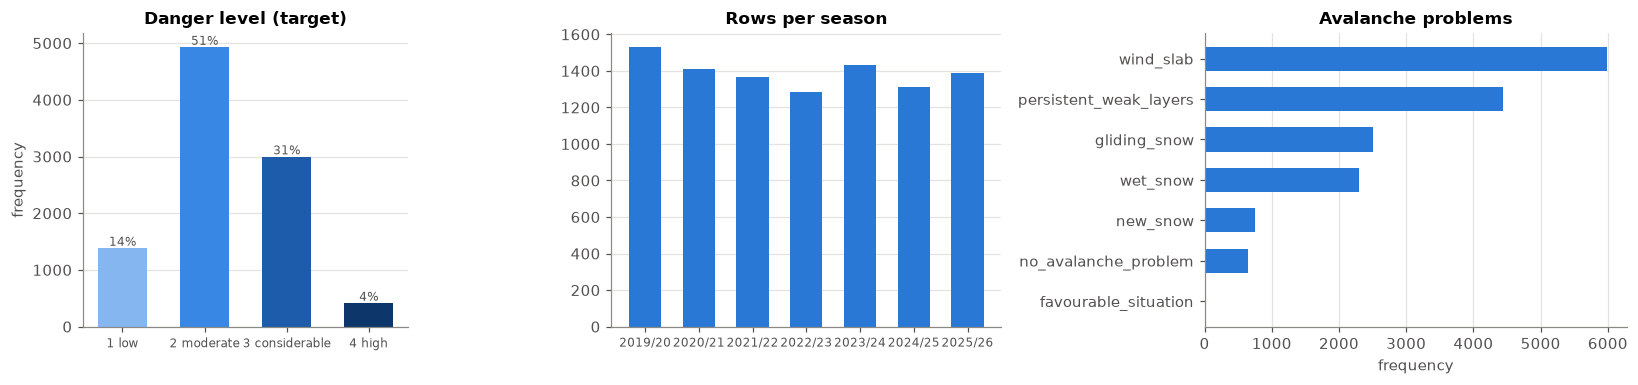

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1.3]})

t = tab_target["frequency"]
axes[0].bar([LEVEL_NAMES[l] for l in t.index], t.values, color=[LEVEL_COLORS[l] for l in t.index], width=0.6)
for i, v in enumerate(t.values):
    axes[0].text(i, v + 40, f"{v / t.sum():.0%}", ha="center", fontsize=8, color="#52514e")
axes[0].set_title("Danger level (target)"); axes[0].set_ylabel("frequency")
axes[0].tick_params(axis="x", labelsize=8)

season_mean = data.groupby("season").size()
axes[1].bar(season_mean.index, season_mean.values, color=BLUE, width=0.6)
axes[1].set_title("Rows per season"); axes[1].tick_params(axis="x", labelsize=8)

prob = data["problems"].str.split(";").explode().value_counts()
axes[2].barh(prob.index, prob.values, color=BLUE, height=0.6)
axes[2].invert_yaxis(); axes[2].set_title("Avalanche problems"); axes[2].set_xlabel("frequency")
for ax in axes[:2]:
    ax.grid(axis="x", visible=False)
axes[2].grid(axis="y", visible=False)
plt.tight_layout()

The bars of the target keep their natural (ordinal) order. For the nominal avalanche problems the order is arbitrary, so they are sorted by frequency, as the lecture allows for bar charts.

### 2.2 Histograms: bin width matters

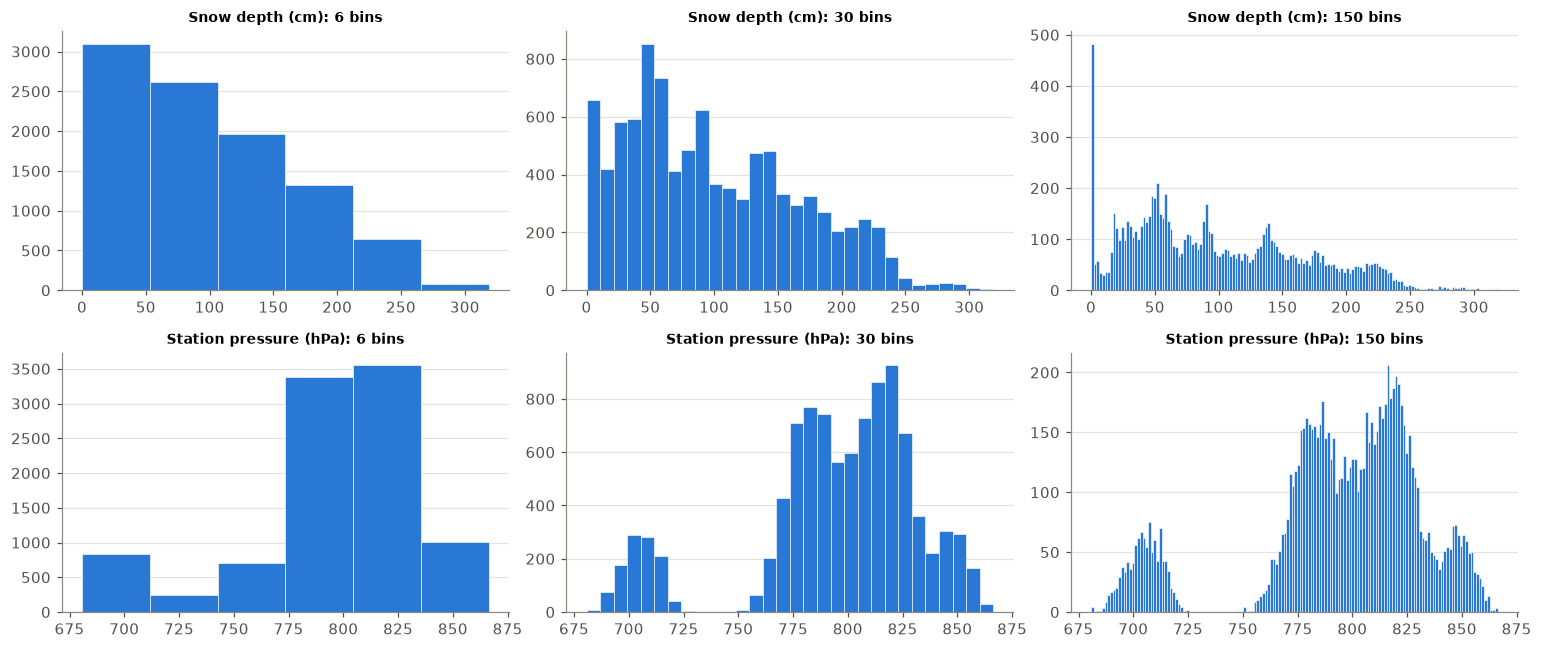

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for row, col in enumerate(["snow_depth_cm", "pressure_mean"]):
    for ax, bins in zip(axes[row], [6, 30, 150]):
        ax.hist(data[col], bins=bins, color=BLUE, edgecolor="white", linewidth=0.4)
        ax.set_title(f"{NUM[col]}: {bins} bins", fontsize=9)
        ax.grid(axis="x", visible=False)
plt.tight_layout()

* With **6 bins**, snow depth looks like one simple right-skewed hump. With **30 bins** a peak at 0 cm (start/end of the season) and a long shoulder appear. With **150 bins** the histogram gets noisy.
* **Pressure** changes most: with 6 bins it looks unimodal and left-skewed, with 30–150 bins it splits into several separate peaks. These are the different station elevations (Pitztaler Gletscher at ~705 hPa, Schmirn at ~847 hPa), not weather.

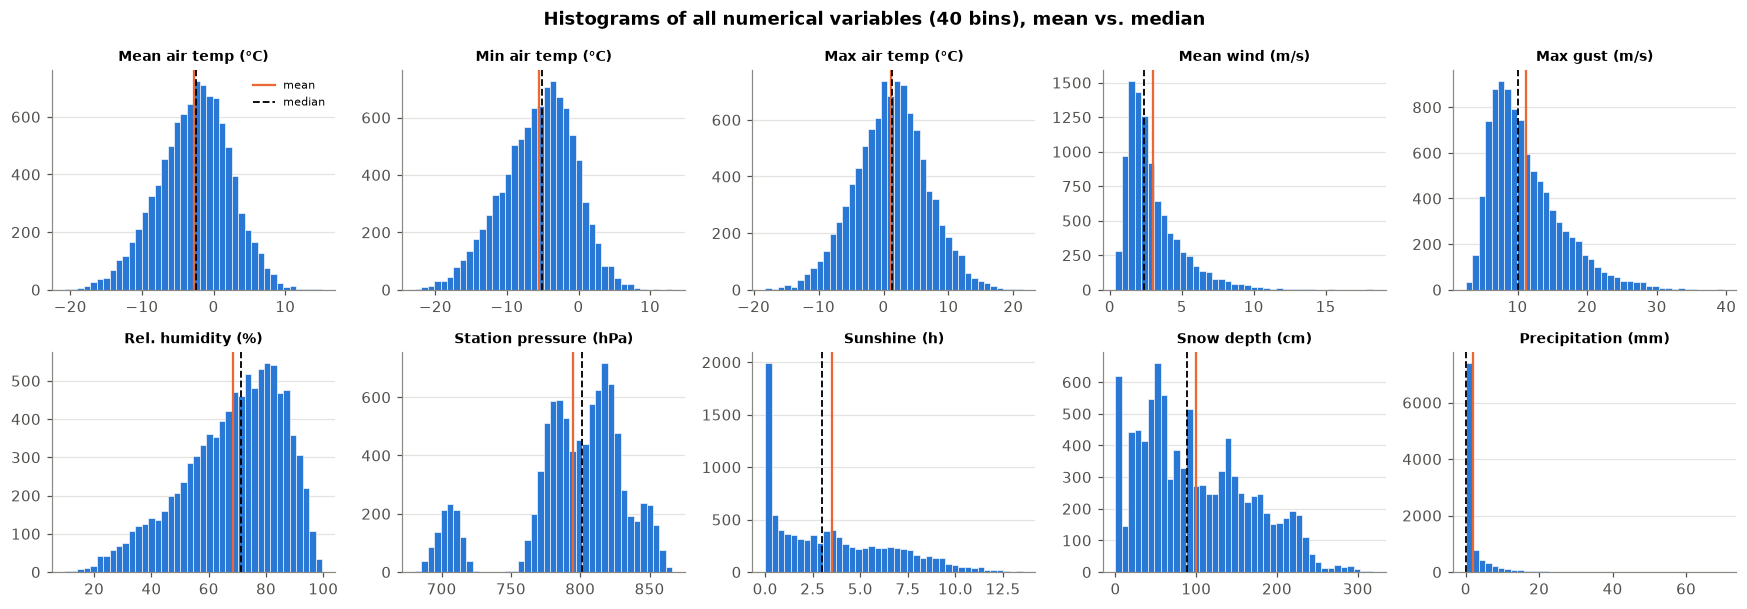

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6))
for ax, (col, label) in zip(axes.flat, NUM.items()):
    ax.hist(data[col], bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    ax.axvline(data[col].mean(), color=ORANGE, lw=1.5, label="mean")
    ax.axvline(data[col].median(), color="black", lw=1.2, ls="--", label="median")
    ax.set_title(label, fontsize=9); ax.grid(axis="x", visible=False)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Histograms of all numerical variables (40 bins), mean vs. median", fontweight="bold")
plt.tight_layout()

The histograms confirm the shape measures of 1.4: the mean lies to the right of the median for precipitation, wind, gusts and snow depth (right skew), and to the left for humidity and pressure (left skew). Precipitation and sunshine have a peak at 0.

### 2.3 Density plots (kernel density estimation): bandwidth matters
We compute a Gaussian KDE ourselves, $\hat f(x) = \frac{1}{nh}\sum_i K\!\left(\frac{x-x_i}{h}\right)$, with the rule-of-thumb bandwidth $h = 1.06\, s\, n^{-1/5}$ (Silverman), and compare it with a much smaller and a much larger bandwidth.

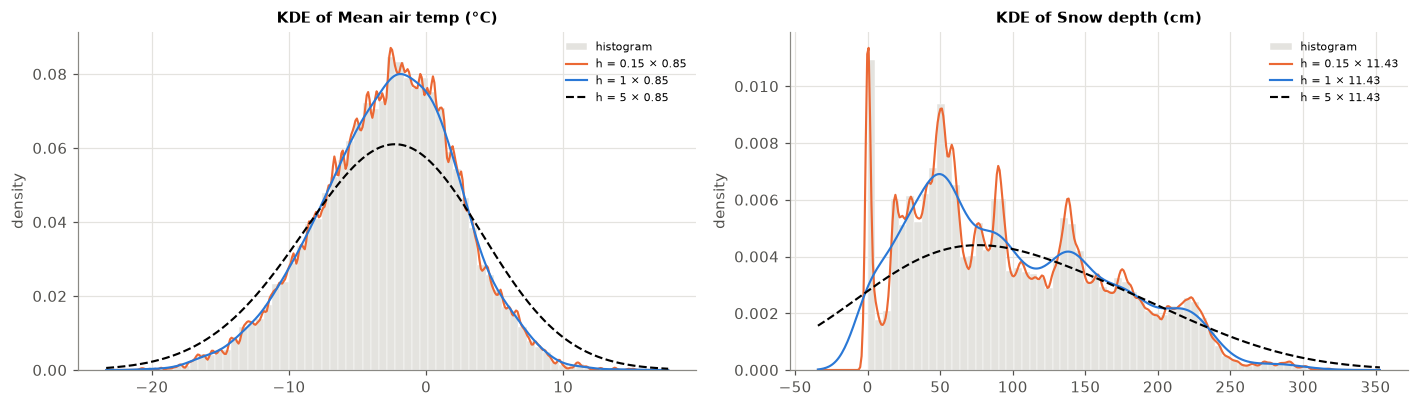

In [16]:
def kde(x, grid, h):
    x = np.asarray(x.dropna())
    u = (grid[:, None] - x[None, :]) / h
    return np.exp(-0.5 * u**2).sum(axis=1) / (len(x) * h * np.sqrt(2 * np.pi))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ["air_temp_mean", "snow_depth_cm"]):
    x = data[col]
    h0 = 1.06 * x.std() * len(x) ** (-1 / 5)
    grid = np.linspace(x.min() - 3 * h0, x.max() + 3 * h0, 400)
    ax.hist(x, bins=60, density=True, color="#e4e3df", edgecolor="white", linewidth=0.3, label="histogram")
    for factor, color, ls in [(0.15, ORANGE, "-"), (1, BLUE, "-"), (5, "black", "--")]:
        ax.plot(grid, kde(x, grid, factor * h0), color=color, ls=ls, lw=1.4, label=f"h = {factor} × {h0:.2f}")
    ax.set_title(f"KDE of {NUM[col]}", fontsize=10); ax.set_ylabel("density")
    ax.legend(fontsize=7, frameon=False)
plt.tight_layout()

* A **too small** bandwidth (orange) produces spurious small bumps. A **too large** bandwidth (dashed) smooths away real structure, e.g. the peak of snow depth near 0 cm and its shoulder.
* With the rule-of-thumb bandwidth, mean temperature is a single smooth, almost symmetric peak. Snow depth is right-skewed with a peak at low values. Note that the KDE extends below 0 cm, which is impossible: the density estimate can go beyond the observed values (as the lecture points out for violin plots).

### 2.4 Boxplots
Box = IQR (Q1 to Q3), line = median, Tukey whiskers = most extreme values within 1.5 × IQR, points beyond = potential outliers. Variables have different units, so each gets its own axis.

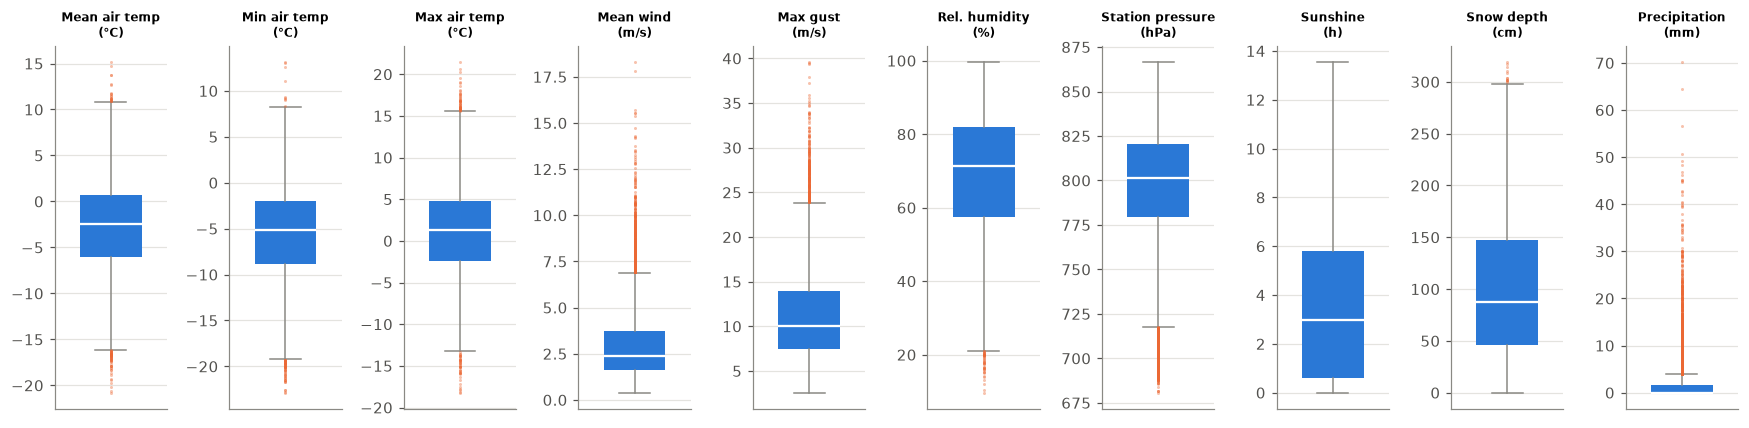

In [17]:
fig, axes = plt.subplots(1, 10, figsize=(16, 4))
for ax, (col, label) in zip(axes, NUM.items()):
    ax.boxplot(data[col].dropna(), widths=0.55, patch_artist=True,
               boxprops={"facecolor": BLUE, "edgecolor": "none"},
               medianprops={"color": "white", "linewidth": 1.5},
               whiskerprops={"color": GREY}, capprops={"color": GREY},
               flierprops={"marker": "o", "markersize": 2, "markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.4})
    ax.set_title(label.replace(" (", "\n("), fontsize=8); ax.set_xticks([])
plt.tight_layout()

The boxplots summarise 1.3 and 1.5 at a glance: many points beyond the whiskers for precipitation, wind speed and gusts (long right tails), many low outliers for humidity and pressure, and few outliers for the temperatures.

### 2.5 Violin plots
A violin plot shows the (mirrored) density, so it adds the shape that the boxplot hides. We compare snow depth and pressure across the 9 stations, because the multimodal histograms suggested a station effect.

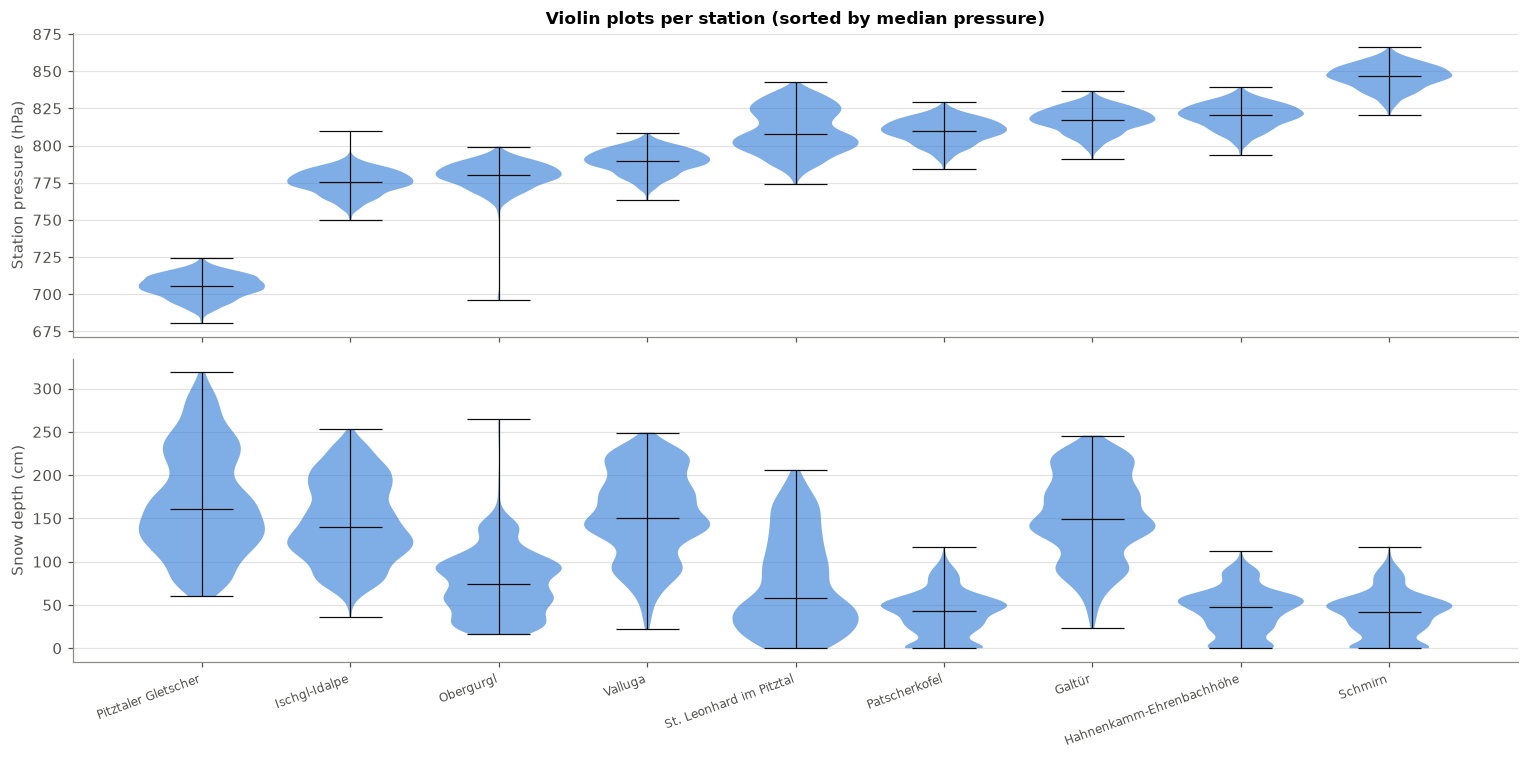

In [18]:
stations = data.groupby("station_name")["pressure_mean"].median().sort_values().index
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col in zip(axes, ["pressure_mean", "snow_depth_cm"]):
    groups = [data.loc[data["station_name"] == s, col].dropna() for s in stations]
    vp = ax.violinplot(groups, showmedians=True, widths=0.85)
    for b in vp["bodies"]:
        b.set_facecolor(BLUE); b.set_edgecolor("none"); b.set_alpha(0.6)
    for k in ["cmedians", "cmins", "cmaxes", "cbars"]:
        vp[k].set_color("#0b0b0b"); vp[k].set_linewidth(0.8)
    ax.set_ylabel(NUM[col]); ax.grid(axis="x", visible=False)
axes[1].set_xticks(range(1, len(stations) + 1), stations, rotation=20, ha="right", fontsize=8)
axes[0].set_title("Violin plots per station (sorted by median pressure)")
plt.tight_layout()

* **Pressure:** each station has its own narrow distribution. The overall multimodal, left-skewed pressure distribution is just the mix of these 9 stations (station elevations). Within one station the spread is small.
* **Snow depth:** the stations differ strongly in level and shape (e.g. Pitztaler Gletscher, Valluga, Galtür, Ischgl with lots of snow; Schmirn, Patscherkofel, Hahnenkamm with little). Some distributions are bimodal (many 0-cm days at the start and end of the season plus a winter peak).

**Consequences:** raw pressure mainly encodes **which station** a row belongs to. For modelling we should use pressure (and possibly snow depth) **relative to the station** (deviation from the station mean, or standardisation per station; DEA-06 "Standardization"), or at least include the region as a feature.

### 2.6 Normal Q–Q plots
Sample quantiles against theoretical normal quantiles (from `statistics.NormalDist`). Points on the line → similar shape to a normal distribution.

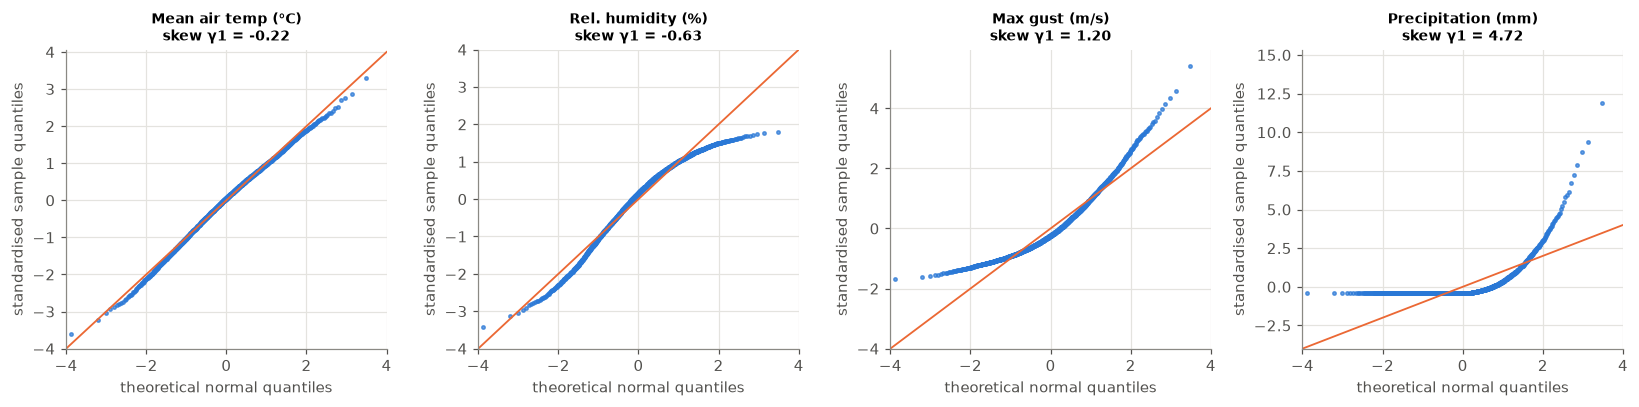

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, ["air_temp_mean", "rel_humidity_mean", "wind_gust_max", "precip_sum_mm"]):
    x = np.sort(data[col].dropna().values)
    n = len(x)
    p = (np.arange(1, n + 1) - 0.5) / n
    theo = np.array([NormalDist().inv_cdf(q) for q in p])
    z = (x - x.mean()) / x.std(ddof=1)
    step = max(1, n // 1500)
    ax.scatter(theo[::step], z[::step], s=5, color=BLUE, alpha=0.7)
    ax.plot([-4, 4], [-4, 4], color=ORANGE, lw=1.2)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, max(4, z.max() + 0.5))
    ax.set_title(f"{NUM[col]}\nskew γ1 = {shape.loc[col, 'skewness γ1']:.2f}", fontsize=9)
    ax.set_xlabel("theoretical normal quantiles"); ax.set_ylabel("standardised sample quantiles")
plt.tight_layout()

* **Mean air temperature** follows the line closely, with only slight deviations in the tails: approximately normal.
* **Humidity** curves below the line at the left end (long left tail, upper limit at 100%).
* **Max gust** curves upwards at the right end (right skew).
* **Precipitation** is far from normal: a flat segment at the bottom (all the dry days, value 0) and a steep upward curve at the top (heavy tail).

**Consequences:** methods that assume normally distributed inputs or errors should not be applied to precipitation, wind or sunshine without transformation. Temperatures can be used as they are.

### 2.7 Stem-and-leaf plot
A stem-and-leaf plot is useful for **small** samples. We use the max gusts at Valluga in January 2026 (31 days): stem = tens, leaf = units (m/s).

In [20]:
def stem_and_leaf(values):
    v = np.sort(np.round(values).astype(int))
    for stem in range(v.min() // 10, v.max() // 10 + 1):
        leaves = "".join(str(x % 10) for x in v if x // 10 == stem)
        print(f"{stem:>3} | {leaves}")

sample = data.loc[(data["station_name"] == "Valluga") & (data["date"].dt.to_period("M") == "2026-01"), "wind_gust_max"]
print(f"n = {len(sample)}, median = {sample.median():.1f} m/s\n")
stem_and_leaf(sample)

n = 31, median = 12.6 m/s

  0 | 7889
  1 | 00001112222333566778889
  2 | 0123


The stem-and-leaf plot keeps the actual values and still shows the shape: most days have gusts of 10–20 m/s at this exposed station, with a few storm days far above. For our 9,729 rows this plot is not useful; the histogram and boxplot do the same job at scale.

### Summary of the univariate analysis
| Variable group | Shape | Consequence |
|---|---|---|
| Danger level | ordinal, imbalanced (51% level 2, 4% level 4, no level 5) | macro-F1/per-class metrics, majority baseline, class weights |
| Temperatures | ≈ normal, few outliers | use as is |
| Precipitation, wind, gusts, sunshine | right-skewed, heavy tails, many zeros (precip/sun) | log transformation / robust scaling for linear models, keep outliers |
| Humidity | left-skewed, bounded at 100% | robust statistics |
| Pressure, snow depth | multimodal because of different stations | normalise per station / add region feature |

---
## 3. Multivariate non-graphical EDA

### 3.1 Cross-tabulation
Contingency tables of categorical variables with the danger level. **Row percentages** answer: *how does the danger level distribution differ across the categories?*

In [21]:
def crosstab_with_pct(row):
    counts = pd.crosstab(data[row], data["danger_max"], margins=True, margins_name="total")
    pct = pd.crosstab(data[row], data["danger_max"], normalize="index") * 100
    return counts, pct

counts, pct = crosstab_with_pct("station_name")
print("counts:"); print(counts.to_string())
print("\nrow percentages:"); pct.round(1)

counts:
danger_max                   1     2     3    4  total
station_name                                          
Galtür                     146   521   354   60   1081
Hahnenkamm-Ehrenbachhöhe   343   532   187   19   1081
Ischgl-Idalpe              137   551   346   47   1081
Obergurgl                  117   560   349   55   1081
Patscherkofel              130   569   346   36   1081
Pitztaler Gletscher        124   539   371   47   1081
Schmirn                    105   550   373   53   1081
St. Leonhard im Pitztal    127   576   342   36   1081
Valluga                    157   531   330   63   1081
total                     1386  4929  2998  416   9729

row percentages:


danger_max,1,2,3,4
station_name,,,,
Galtür,13.5,48.2,32.7,5.6
Hahnenkamm-Ehrenbachhöhe,31.7,49.2,17.3,1.8
Ischgl-Idalpe,12.7,51.0,32.0,4.3
Obergurgl,10.8,51.8,32.3,5.1
Patscherkofel,12.0,52.6,32.0,3.3
Pitztaler Gletscher,11.5,49.9,34.3,4.3
Schmirn,9.7,50.9,34.5,4.9
St. Leonhard im Pitztal,11.7,53.3,31.6,3.3
Valluga,14.5,49.1,30.5,5.8


In [22]:
for row in ["season", "month", "tendency", "days_before"]:
    _, pct = crosstab_with_pct(row)
    if row == "month":
        pct = pct.reindex([11, 12, 1, 2, 3, 4, 5])
    print(f"--- danger level by {row} (row %)")
    print(pct.round(1).to_string(), "\n")

--- danger level by season (row %)
danger_max     1     2     3    4
season                           
2019/20     19.4  56.7  19.5  4.4
2020/21      2.7  40.8  50.1  6.4
2021/22     21.8  44.1  28.7  5.5
2022/23      7.5  51.8  37.9  2.8
2023/24      7.5  60.9  28.7  2.9
2024/25     23.9  59.0  15.9  1.2
2025/26     17.0  41.0  35.5  6.5 

--- danger level by month (row %)
danger_max     1     2     3    4
month                            
11          15.9  45.4  33.8  4.8
12          14.4  41.3  37.7  6.6
1           15.8  53.7  25.5  5.1
2           11.3  38.8  40.8  9.0
3           19.7  54.1  25.3  0.8
4           10.0  64.0  25.4  0.6
5            7.2  58.2  34.6  0.0 

--- danger level by tendency (row %)
danger_max     1     2     3     4
tendency                          
decreasing   1.1  36.8  51.8  10.3
increasing  20.5  50.0  26.7   2.9
steady      14.9  52.4  29.0   3.8 

--- danger level by days_before (row %)
danger_max      1     2     3     4
days_before              

In [23]:
# Previous day's level (known before the bulletin) vs. today's level: a cross-tab of two categorical variables
prev = data["prev_danger"]
trans = pd.crosstab(prev.rename("level yesterday"), data["danger_max"].rename("level today"), normalize="index") * 100
print(f"level unchanged from the previous day: {(prev == data['danger_max'])[prev.notna()].mean():.1%}")
trans.round(1)

level unchanged from the previous day: 79.2%


level today,1,2,3,4
level yesterday,,,,
1.0,79.1,19.0,1.3,0.6
2.0,6.1,82.9,10.5,0.6
3.0,0.0,19.6,75.9,4.5
4.0,0.0,0.0,41.6,58.4


* **Regions:** 8 of 9 regions have very similar distributions. Kitzbüheler Alpen (station Hahnenkamm, the lowest station) has about twice as many level-1 days and fewer level-3/4 days.
* **Seasons:** the share of level-4 days varies several-fold between winters (e.g. ~1% in 2024/25 vs. ~6.5% in 2025/26). The test season will therefore look different from the training seasons.
* **Months:** level 4 is most frequent in February (9%) and December (6.6%), and almost never occurs from March on (< 1%). In spring level 2 dominates (54–64%).
* **`days_before`:** bulletins published on the morning of the valid day have much higher levels. These are updates in critical situations. `days_before` is only known after publication, so it cannot be a feature.
* **Yesterday's level:** about 79% of days keep the previous day's level.

**Consequences:** region and month/season are useful categorical features. The model must beat a **persistence baseline** (predict yesterday's level, ~79% accuracy), not just the majority class. Train/test must be split **by season**, because neighbouring days are almost identical.

### 3.2 Univariate statistics by category
Summary statistics of each numerical variable **per danger level**. As the lecture recommends, we compare location *and* spread and keep the group sizes in view (level 4 has only 416 rows).

In [24]:
key = ["precip_sum_mm", "wind_gust_max", "rel_humidity_mean", "sunshine_sum", "snow_depth_cm", "air_temp_mean"]
by_level = data.groupby("danger_max")[key].agg(["median", lambda x: x.quantile(.75) - x.quantile(.25)])
by_level.columns = [f"{c} {'IQR' if s == '<lambda_0>' else s}" for c, s in by_level.columns]
by_level.insert(0, "n", data.groupby("danger_max").size())
by_level.T

danger_max,1,2,3,4
n,1386.00,4929.00,2998.00,416.00
precip_sum_mm median,0.00,0.00,0.41,6.40
precip_sum_mm IQR,0.00,0.93,3.32,12.03
wind_gust_max median,8.57,9.58,11.30,15.73
wind_gust_max IQR,4.55,5.87,7.99,9.31
rel_humidity_mean median,61.15,69.54,76.22,83.95
rel_humidity_mean IQR,24.97,24.30,19.79,12.52
sunshine_sum median,4.40,3.31,1.98,0.02
sunshine_sum IQR,4.77,5.14,4.55,0.89
snow_depth_cm median,69.36,79.72,98.92,127.08


In [25]:
# Mean, std and group size per level for all numerical variables
data.groupby("danger_max")[list(NUM)].agg(["mean", "std"]).T.round(2)

danger_max                   1       2       3       4
air_temp_mean     mean   -1.84   -2.42   -3.35   -4.97
                  std     4.46    4.93    5.30    4.27
air_temp_min      mean   -4.65   -5.33   -6.17   -7.57
                  std     4.71    4.97    5.31    4.45
air_temp_max      mean    2.08    1.63    0.38   -2.07
                  std     4.61    5.44    5.84    4.76
wind_speed_mean   mean    2.59    2.81    3.24    4.24
                  std     1.57    1.79    2.12    2.64
wind_gust_max     mean    9.24   10.60   12.53   16.55
                  std     3.53    4.58    5.70    6.80
rel_humidity_mean mean   60.47   67.05   72.87   80.91
                  std    17.35   17.02   15.59   12.61
pressure_mean     mean  800.85  795.46  791.08  788.89
                  std    35.47   38.59   40.73   39.63
sunshine_sum      mean    4.77    3.80    2.84    0.90
                  std     3.14    3.10    2.88    1.79
snow_depth_cm     mean   81.21   95.65  109.13  128.84
                  std    57.64   69.06   67.66   61.01
precip_sum_mm     mean    0.30    1.14    2.80    9.89
                  std     1.11    2.69    5.33   10.69

* From level 1 to level 4, the median **precipitation** rises from 0 to ~6 mm, **gusts** from ~9 to ~16 m/s, **humidity** from ~61% to ~84%, **snow depth** from ~69 to ~127 cm, while **sunshine** falls from ~4.4 h to ~0 h and **temperature** falls by ~3 °C.
* The **spread** of precipitation and gusts grows with the level as well (the IQR of precipitation rises from 0 to ~12 mm). High-danger days are more variable, not just shifted. For humidity and sunshine the spread *shrinks* at level 4: high-danger days are almost always humid and overcast.
* The differences between neighbouring levels (especially 2 vs. 3) are small compared to the spread within each level, so no single variable separates the classes.

### 3.3 Covariance and correlation
Sample covariance $s_{XY} = \frac{1}{n-1}\sum (x_i-\bar x)(y_i-\bar y)$ and Pearson correlation $r = \frac{s_{XY}}{s_X s_Y}$, computed from the formulas and checked against pandas.

In [26]:
def sample_cov(x, y):
    return ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)

x, y = data["precip_sum_mm"], data["danger_max"]
s_xy = sample_cov(x, y)
r = s_xy / (x.std() * y.std())
print(f"cov(precip, danger) = {s_xy:.3f} mm·level   (pandas: {x.cov(y):.3f})")
print(f"r(precip, danger)   = {r:.3f}             (pandas: {x.corr(y):.3f})")

cov(precip, danger) = 1.187 mm·level   (pandas: 1.187)
r(precip, danger)   = 0.346             (pandas: 0.346)


In [27]:
COLS = list(NUM) + ["danger_max"]
cov = data[COLS].cov()
print("Covariance matrix (units differ, so magnitudes cannot be compared):")
cov.round(1)

Covariance matrix (units differ, so magnitudes cannot be compared):


,air_temp_mean,air_temp_min,air_temp_max,wind_speed_mean,wind_gust_max,rel_humidity_mean,pressure_mean,sunshine_sum,snow_depth_cm,precip_sum_mm,danger_max
air_temp_mean,25.1,24.5,26.1,-1.0,-3.1,-18.6,82.1,3.4,-111.9,-1.4,-0.5
air_temp_min,24.5,25.6,23.8,-0.6,-2.5,-13.0,74.9,2.3,-106.6,-0.7,-0.5
air_temp_max,26.1,23.8,30.4,-1.9,-5.2,-25.9,97.1,5.6,-124.5,-2.7,-0.6
wind_speed_mean,-1.0,-0.6,-1.9,3.8,7.7,5.0,-11.7,-1.3,30.7,2.0,0.2
wind_gust_max,-3.1,-2.5,-5.2,7.7,26.9,19.4,-63.5,-4.8,87.6,8.2,1.1
rel_humidity_mean,-18.6,-13.0,-25.9,5.0,19.4,294.0,60.6,-29.7,-58.1,32.2,3.6
pressure_mean,82.1,74.9,97.1,-11.7,-63.5,60.6,1522.8,-6.8,-1221.4,-10.6,-2.5
sunshine_sum,3.4,2.3,5.6,-1.3,-4.8,-29.7,-6.8,9.7,-1.8,-4.9,-0.6
snow_depth_cm,-111.9,-106.6,-124.5,30.7,87.6,-58.1,-1221.4,-1.8,4578.5,30.6,8.2
precip_sum_mm,-1.4,-0.7,-2.7,2.0,8.2,32.2,-10.6,-4.9,30.6,21.1,1.2


In [28]:
corr = data[COLS].corr()          # Pearson
corr.round(2)

,air_temp_mean,air_temp_min,air_temp_max,wind_speed_mean,wind_gust_max,rel_humidity_mean,pressure_mean,sunshine_sum,snow_depth_cm,precip_sum_mm,danger_max
air_temp_mean,1.00,0.97,0.94,-0.10,-0.12,-0.22,0.42,0.22,-0.33,-0.06,-0.14
air_temp_min,0.97,1.00,0.85,-0.06,-0.10,-0.15,0.38,0.14,-0.31,-0.03,-0.13
air_temp_max,0.94,0.85,1.00,-0.18,-0.18,-0.27,0.45,0.33,-0.33,-0.11,-0.16
wind_speed_mean,-0.10,-0.06,-0.18,1.00,0.77,0.15,-0.15,-0.21,0.23,0.22,0.17
wind_gust_max,-0.12,-0.10,-0.18,0.77,1.00,0.22,-0.31,-0.30,0.25,0.35,0.29
rel_humidity_mean,-0.22,-0.15,-0.27,0.15,0.22,1.00,0.09,-0.56,-0.05,0.41,0.28
pressure_mean,0.42,0.38,0.45,-0.15,-0.31,0.09,1.00,-0.06,-0.46,-0.06,-0.08
sunshine_sum,0.22,0.14,0.33,-0.21,-0.30,-0.56,-0.06,1.00,-0.01,-0.34,-0.26
snow_depth_cm,-0.33,-0.31,-0.33,0.23,0.25,-0.05,-0.46,-0.01,1.00,0.10,0.16
precip_sum_mm,-0.06,-0.03,-0.11,0.22,0.35,0.41,-0.06,-0.34,0.10,1.00,0.35


In [29]:
def strength(r):
    a = abs(r)
    return ("no" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong" if a < 0.7 else "very strong")

target_corr = corr["danger_max"].drop("danger_max").sort_values(key=abs, ascending=False).to_frame("r with danger_max")
target_corr["direction"] = np.where(target_corr["r with danger_max"] > 0, "positive", "negative")
target_corr["description (slide 46)"] = target_corr["r with danger_max"].map(strength) + " linear relationship"
target_corr

,r with danger_max,direction,description (slide 46)
precip_sum_mm,0.35,positive,moderate linear relationship
wind_gust_max,0.29,positive,weak linear relationship
rel_humidity_mean,0.28,positive,weak linear relationship
sunshine_sum,-0.26,negative,weak linear relationship
wind_speed_mean,0.17,positive,weak linear relationship
snow_depth_cm,0.16,positive,weak linear relationship
air_temp_max,-0.16,negative,weak linear relationship
air_temp_mean,-0.14,negative,weak linear relationship
air_temp_min,-0.13,negative,weak linear relationship
pressure_mean,-0.08,negative,no linear relationship


In [30]:
pairs = corr.drop(index="danger_max", columns="danger_max")
pairs = (pairs.where(np.triu(np.ones(pairs.shape, dtype=bool), k=1)).stack()
              .rename("r").reset_index().rename(columns={"level_0": "variable A", "level_1": "variable B"}))
pairs["description"] = pairs["r"].map(strength)
pairs.loc[pairs["r"].abs() >= 0.5].sort_values("r", key=abs, ascending=False)

,variable A,variable B,r,description
1,air_temp_mean,air_temp_min,0.97,very strong
2,air_temp_mean,air_temp_max,0.94,very strong
12,air_temp_min,air_temp_max,0.85,very strong
34,wind_speed_mean,wind_gust_max,0.77,very strong
57,rel_humidity_mean,sunshine_sum,-0.56,strong


* The **covariance matrix** is hard to read: pressure and snow depth have huge variances only because of their units/scale. This is why we interpret the **correlation matrix** instead.
* Correlation with the danger level (Pearson, treating the ordinal level as numeric): only **precipitation** reaches a *moderate* linear relationship (r = 0.35). Gusts, humidity, sunshine (negative), wind, snow depth and temperature are *weak*, and pressure shows *no* linear relationship. No variable has a strong linear relationship with the target.
* **Pairs of predictors:** the three temperatures are very strongly correlated with each other (r > 0.85), and so are mean wind and gusts. Sunshine is strongly negatively correlated with humidity. These variables carry largely the same information (redundancy).
* As the lecture warns: r ≈ 0 does not mean independence, a nonlinear relationship can still exist (checked graphically in Section 4). And correlation is not causation: high humidity does not *cause* avalanches, it comes with snowfall.

**Consequences:** for linear models keep only one variable per highly correlated group (e.g. `air_temp_mean`, `wind_gust_max`), otherwise the coefficients are unstable. Because no single feature is strongly related to the target, the model has to combine several weak signals.

---
## 4. Multivariate graphical EDA

### 4.1 Univariate graph per category: grouped boxplots

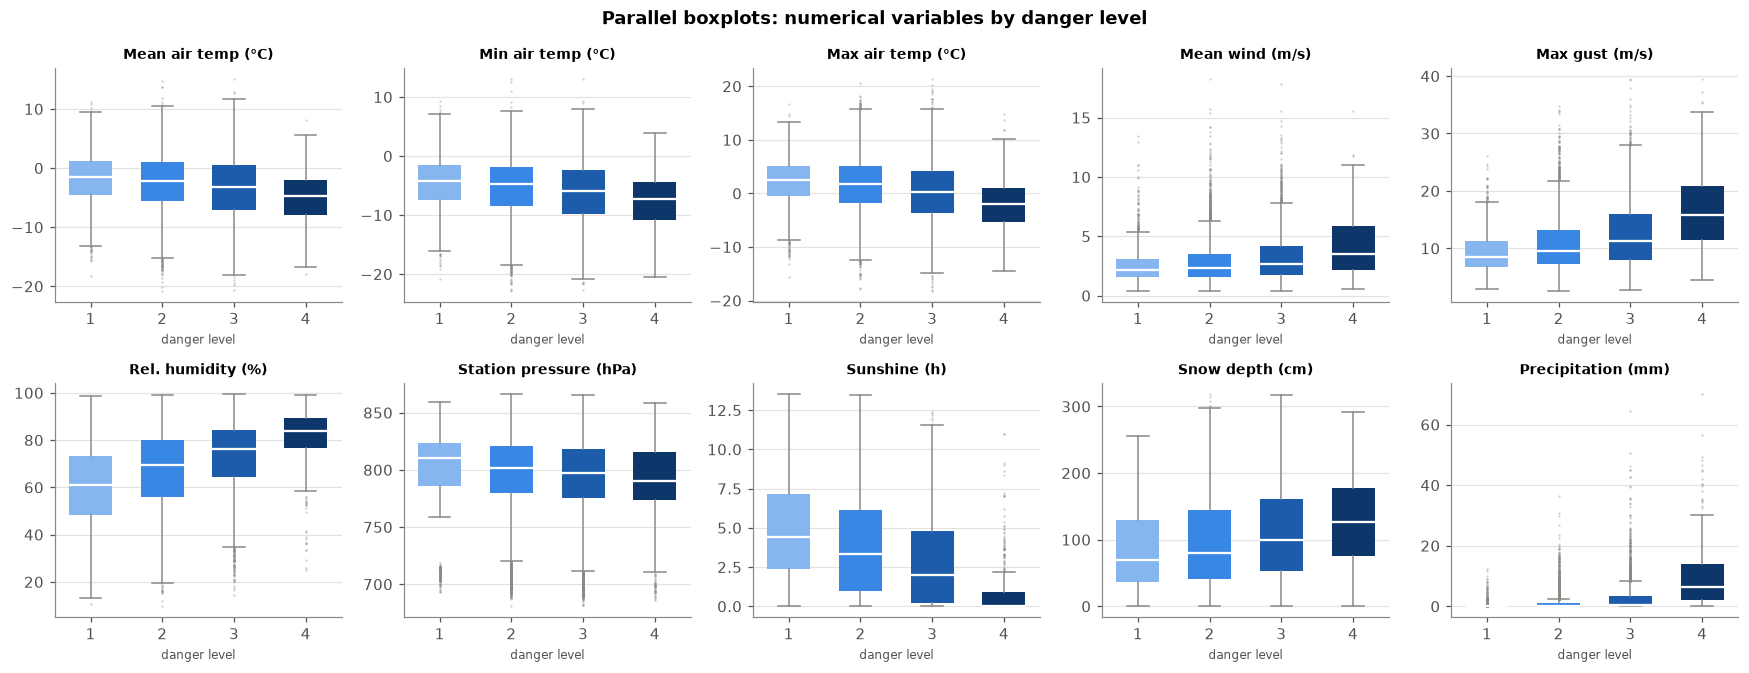

In [31]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2))
for ax, (col, label) in zip(axes.flat, NUM.items()):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in LEVELS]
    bp = ax.boxplot(groups, tick_labels=LEVELS, widths=0.6, patch_artist=True,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": GREY}, capprops={"color": GREY},
                    flierprops={"marker": "o", "markersize": 1.5, "markerfacecolor": GREY, "markeredgecolor": "none", "alpha": 0.4})
    for patch, l in zip(bp["boxes"], LEVELS):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(label, fontsize=9); ax.set_xlabel("danger level", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Parallel boxplots: numerical variables by danger level", fontweight="bold")
plt.tight_layout()

* Precipitation, gusts, humidity and snow depth shift **upwards** and sunshine **downwards** with increasing level. The boxes of neighbouring levels overlap a lot, especially 2 and 3, which matches the weak-to-moderate correlations.
* The **spread** also changes: precipitation and gusts become much more variable at levels 3–4. As the lecture says, differences in spread can be as important as differences in location.
* Pressure shows almost no difference between the levels, because the station effect (2.5) dominates.

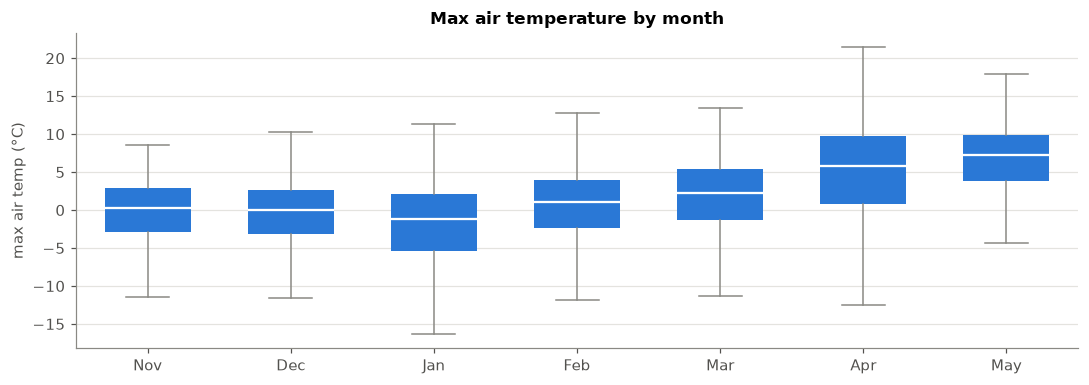

In [32]:
# The same idea for a categorical × numerical pair where the category is not the target: temperature by month
months = [11, 12, 1, 2, 3, 4, 5]
fig, ax = plt.subplots(figsize=(10, 3.6))
groups = [data.loc[data["month"] == m, "air_temp_max"] for m in months]
bp = ax.boxplot(groups, tick_labels=["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"], widths=0.6, patch_artist=True,
                showfliers=False, medianprops={"color": "white", "linewidth": 1.5},
                whiskerprops={"color": GREY}, capprops={"color": GREY})
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE, edgecolor="none")
ax.set_ylabel("max air temp (°C)"); ax.set_title("Max air temperature by month"); ax.grid(axis="x", visible=False)
plt.tight_layout()

Temperature depends strongly on the month (cold mid-winter, warm spring). This matters for the next section, because the month is a possible confounder of the temperature–danger relationship.

### 4.2 Scatterplots and subgroups

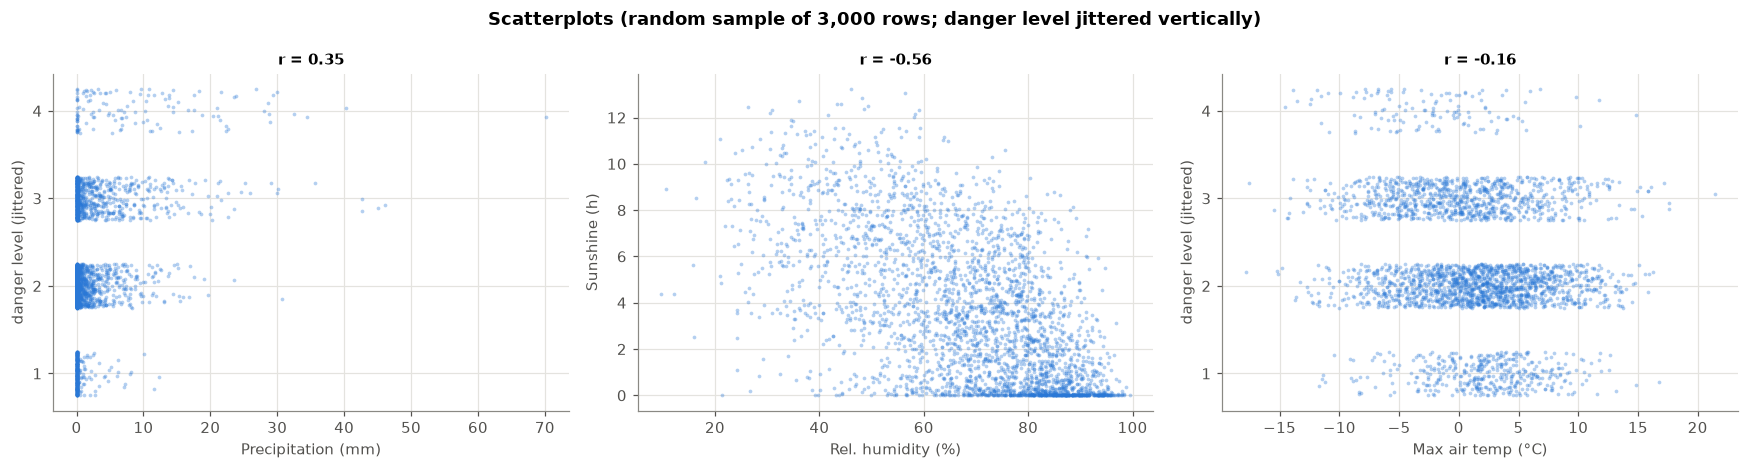

In [33]:
rng = np.random.default_rng(0)
sub = data.sample(3000, random_state=0)
jit = rng.uniform(-0.25, 0.25, len(sub))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
pairs_to_plot = [("precip_sum_mm", "danger_max"), ("rel_humidity_mean", "sunshine_sum"), ("air_temp_max", "danger_max")]
for ax, (xc, yc) in zip(axes, pairs_to_plot):
    yy = sub[yc] + (jit if yc == "danger_max" else 0)
    ax.scatter(sub[xc], yy, s=6, alpha=0.35, color=BLUE, lw=0)
    ax.set_xlabel(NUM.get(xc, xc)); ax.set_ylabel(NUM.get(yc, "danger level (jittered)"))
    ax.set_title(f"r = {data[xc].corr(data[yc]):.2f}", fontsize=10)
    if yc == "danger_max":
        ax.set_yticks(LEVELS)
fig.suptitle("Scatterplots (random sample of 3,000 rows; danger level jittered vertically)", fontweight="bold")
plt.tight_layout()

* **Precipitation vs. danger:** dry days occur at every level, but days with a lot of precipitation are almost never level 1. The relationship is not linear: it looks more like "heavy precipitation → high level", while low precipitation says little.
* **Humidity vs. sunshine:** a clear negative, slightly curved relationship (humid days are overcast). This is the redundancy found in 3.3.
* **Max temperature vs. danger:** almost no visible linear trend (r is weak), but the warmest days in the data (> 10 °C) are not level 1 either. Section 4.3 shows why.

**Subgroups matter.** The lecture shows that the overall association can differ from the associations within groups. We test this with two subgroup variables from our data: **station** and **month**.

,Galtür,Hahnenkamm-Ehrenbachhöhe,Ischgl-Idalpe,Obergurgl,Patscherkofel,Pitztaler Gletscher,Schmirn,St. Leonhard im Pitztal,Valluga
"r(pressure, snow depth) within station",0.08,0.01,0.06,-0.04,0.01,0.03,0.04,0.72,0.07


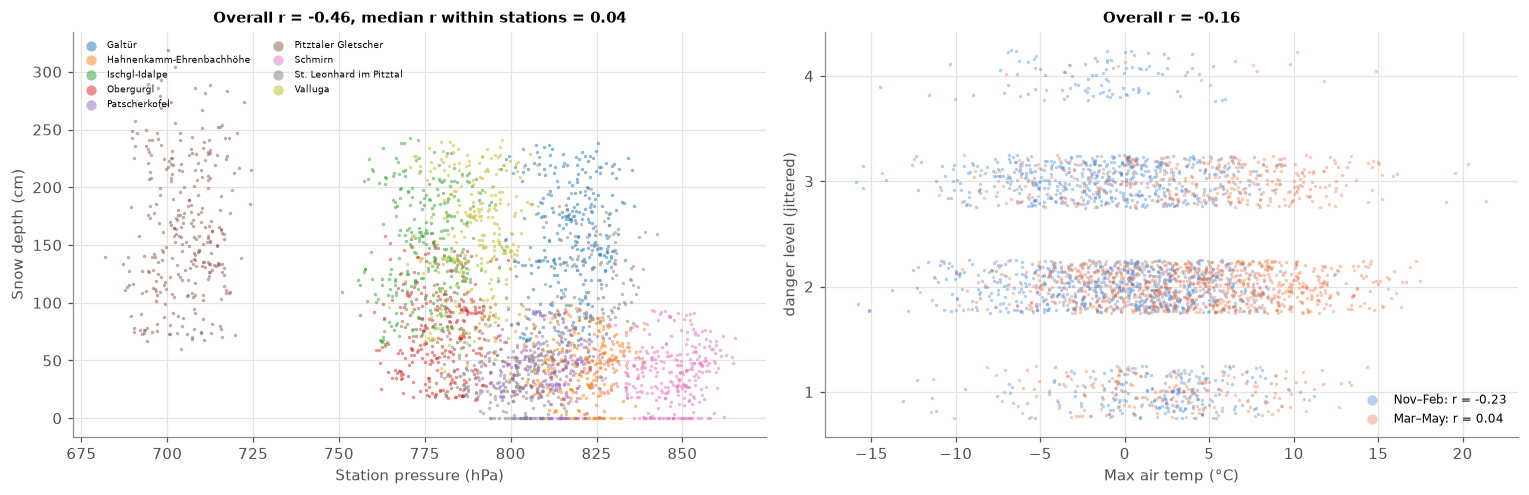

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) snow depth vs. pressure: overall vs. within each station
ax = axes[0]
cmap = plt.get_cmap("tab10")
within = {}
for i, (st, g) in enumerate(data.groupby("station_name")):
    s = g.sample(min(len(g), 300), random_state=0)
    ax.scatter(s["pressure_mean"], s["snow_depth_cm"], s=5, alpha=0.5, color=cmap(i), lw=0, label=st)
    within[st] = g["pressure_mean"].corr(g["snow_depth_cm"])
ax.set_xlabel(NUM["pressure_mean"]); ax.set_ylabel(NUM["snow_depth_cm"])
ax.set_title(f"Overall r = {data['pressure_mean'].corr(data['snow_depth_cm']):.2f}, "
             f"median r within stations = {np.median(list(within.values())):.2f}", fontsize=10)
ax.legend(fontsize=6, frameon=False, markerscale=3, ncol=2, loc="upper left")

# (b) temperature vs. danger level: within early winter vs. spring
ax = axes[1]
spring = data["spring"]
for mask, color, name in [(~spring, BLUE, "Nov–Feb"), (spring, ORANGE, "Mar–May")]:
    g = data[mask]
    s = g.sample(1500, random_state=0)
    ax.scatter(s["air_temp_max"], s["danger_max"] + rng.uniform(-0.25, 0.25, len(s)), s=5, alpha=0.35, color=color, lw=0,
               label=f"{name}: r = {g['air_temp_max'].corr(g['danger_max']):.2f}")
ax.set_yticks(LEVELS); ax.set_xlabel(NUM["air_temp_max"]); ax.set_ylabel("danger level (jittered)")
ax.set_title(f"Overall r = {data['air_temp_max'].corr(data['danger_max']):.2f}", fontsize=10)
ax.legend(fontsize=8, frameon=False, markerscale=3)
plt.tight_layout()

pd.Series(within, name="r(pressure, snow depth) within station").round(2).to_frame().T

* **(a) Pressure vs. snow depth:** across all rows there is a moderate negative correlation (r = −0.46): "low pressure → more snow". But within 8 of the 9 stations r is ≈ 0 (−0.04 … 0.08). The overall r is an **aggregation effect**: high stations have *both* lower pressure and more snow. The station (elevation) is a **confounder**. (St. Leonhard im Pitztal is the exception with r = 0.72 within the station, which is worth a check in the raw station data.)
* **(b) Temperature vs. danger:** in mid-winter (Nov–Feb) warmer days tend to have *lower* danger (r ≈ −0.23; cold days come with storms and new snow). In spring (Mar–May) the relationship disappears (r ≈ 0.04; warm days also bring wet-snow danger). The weak overall r hides two different relationships in the subgroups.

**Consequences:** the station/region and the month (or season phase) must be available to the model. A model that can learn interactions (e.g. trees) is better suited than one global linear temperature effect. Alternatively, an interaction feature temperature × spring could be added for a linear model.

### 4.3 Scatterplot matrix
Pairwise scatterplots of the most relevant variables (diagonal: histograms, y-axis = counts), coloured by danger level, as a random sample of 1,500 rows.

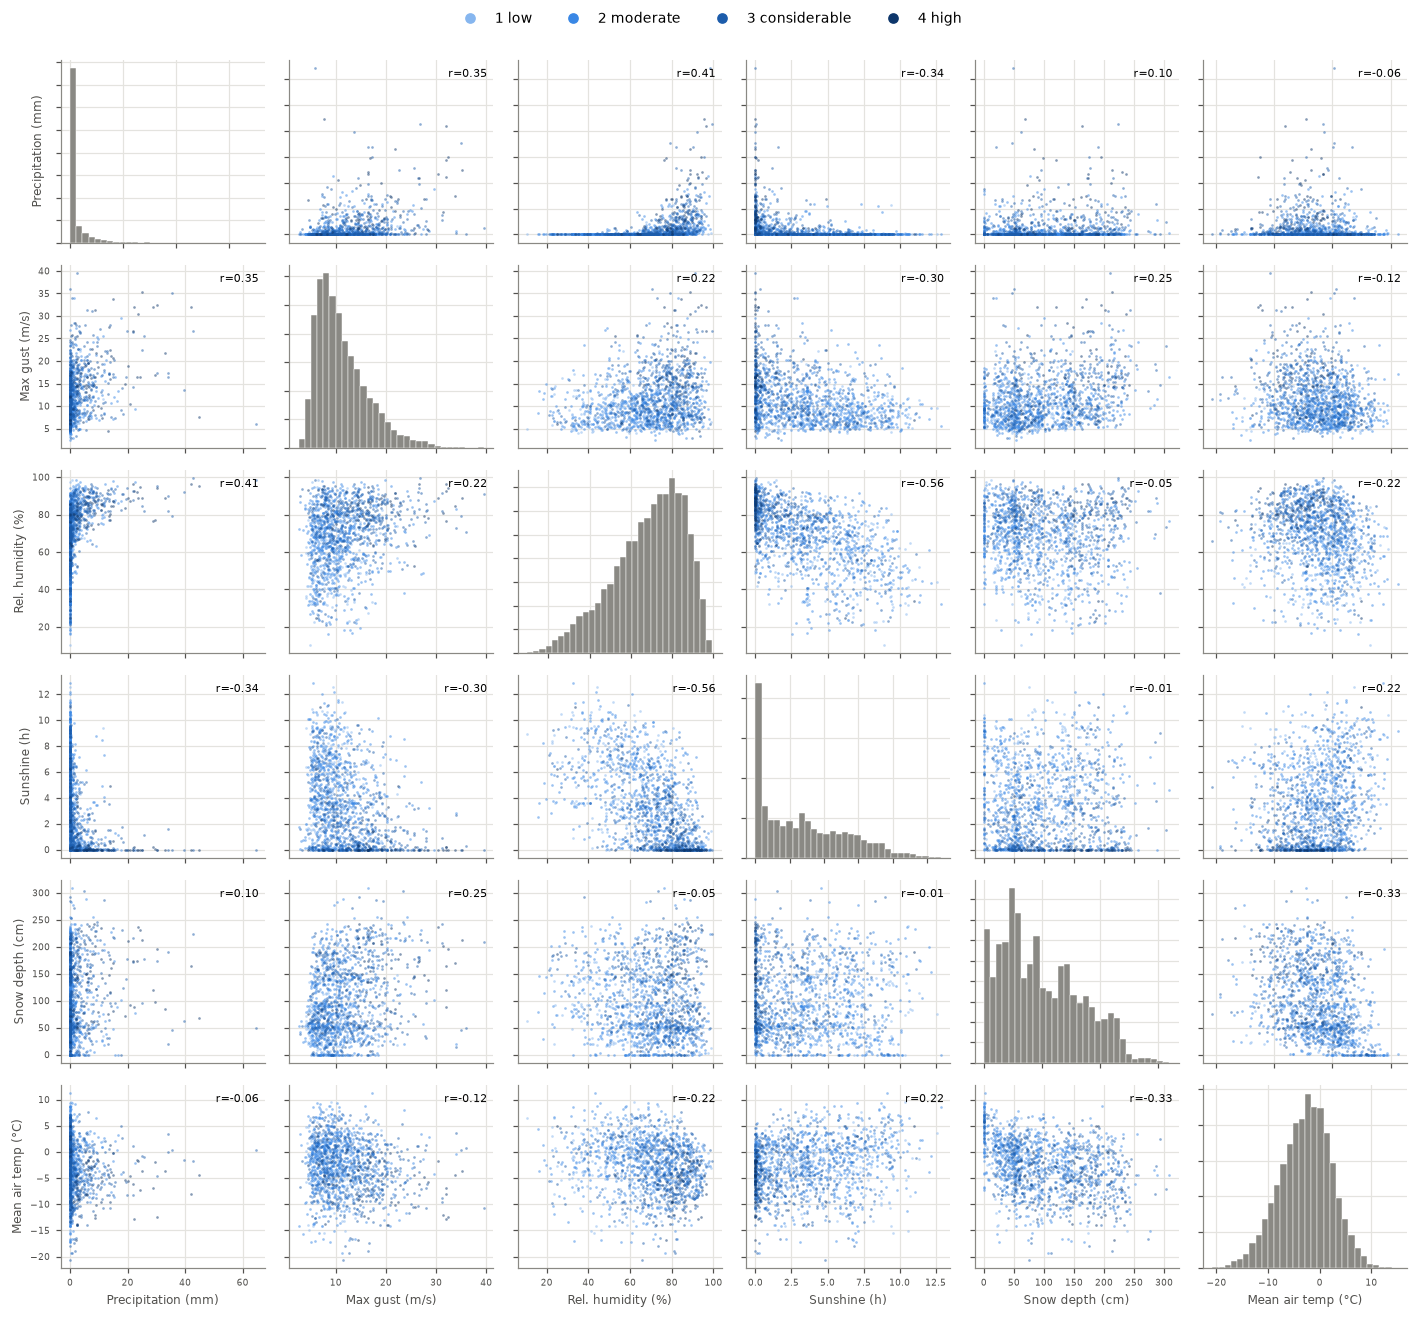

In [35]:
SPM = ["precip_sum_mm", "wind_gust_max", "rel_humidity_mean", "sunshine_sum", "snow_depth_cm", "air_temp_mean"]
s = data.sample(1500, random_state=1)
k = len(SPM)
fig, axes = plt.subplots(k, k, figsize=(13, 12))
for i, yc in enumerate(SPM):
    for j, xc in enumerate(SPM):
        ax = axes[i, j]
        if i == j:
            ax.hist(data[xc], bins=30, color=GREY, edgecolor="white", linewidth=0.3)
        else:
            for l in LEVELS:
                m = s["danger_max"] == l
                ax.scatter(s.loc[m, xc], s.loc[m, yc], s=3, alpha=0.5, color=LEVEL_COLORS[l], lw=0)
            ax.text(0.97, 0.95, f"r={data[xc].corr(data[yc]):.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=7)
        ax.tick_params(labelsize=6)
        if i == k - 1: ax.set_xlabel(NUM[xc], fontsize=8)
        else: ax.set_xticklabels([])
        if j == 0: ax.set_ylabel(NUM[yc], fontsize=8)
        if j > 0 or i == j: ax.set_yticklabels([])   # diagonal y-axis = counts, not the variable
handles = [plt.Line2D([], [], marker="o", ls="", color=LEVEL_COLORS[l], label=LEVEL_NAMES[l]) for l in LEVELS]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.97))

* The darkest points (levels 3–4) cluster where **precipitation, gusts and humidity are high and sunshine is low**, i.e. on stormy days. Level-1 points are concentrated on dry, sunny days.
* Several relationships are clearly **nonlinear** (precipitation vs. humidity: precipitation is only > 0 above a humidity threshold), which r does not capture.
* The levels still overlap in every 2-D view, so a model needs several variables together, and even then 2 vs. 3 will be hard to separate.

### 4.4 Correlation heatmap
The heatmap of the Pearson correlation matrix from 3.3, to see the patterns at a glance.

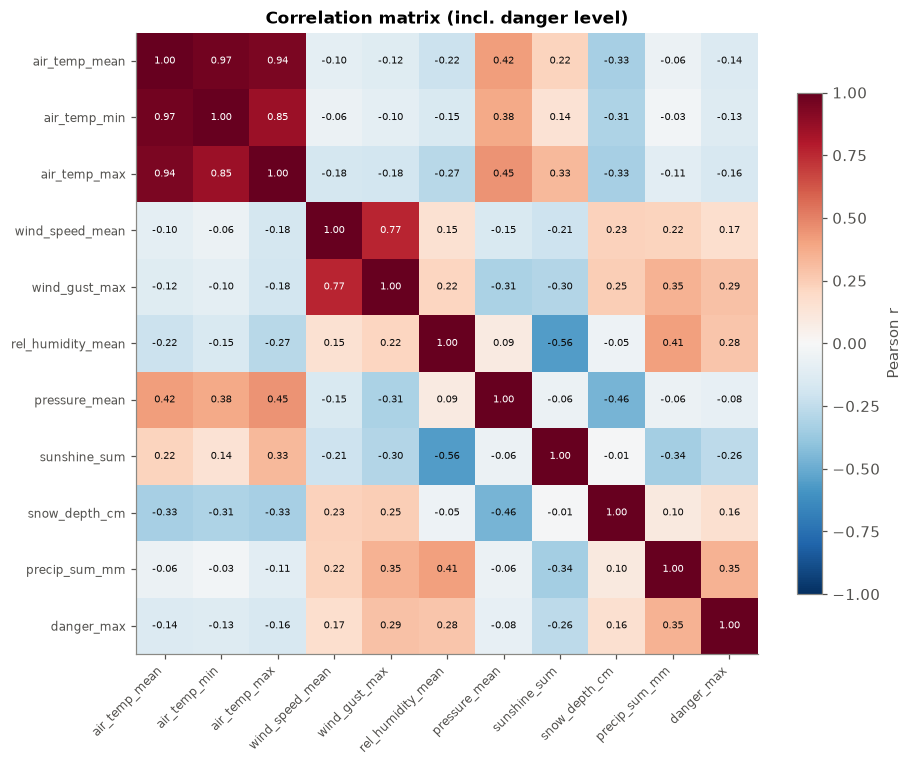

In [36]:
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix (incl. danger level)")
plt.tight_layout()

Two blocks stand out: a **temperature block** (mean/min/max, very strongly positive) and a **"storm" block** (precipitation, humidity, gusts, wind positive with each other and negative with sunshine). The danger level (last row) belongs to the storm block. As the lecture notes, the heatmap is only a summary, and the important pairs were inspected as scatterplots in 4.2 and 4.3.

### 4.5 Engineered features
The features from the feature engineering block, analysed with the same lecture methods: correlation (compared to the raw variable), grouped boxplots, histogram + Q–Q plot for the log transformation, and a correlation matrix to check for redundancy.

In [37]:
rows = []
for feat, raw in ENG_NUM.items():
    r_eng = data[feat].corr(data["danger_max"])
    r_raw = data[raw].corr(data["danger_max"])
    rows.append({"feature": feat, "built from": raw, "r engineered": r_eng, "r raw": r_raw,
                 "|r| gain": abs(r_eng) - abs(r_raw), "description": strength(r_eng)})
rows.append({"feature": "prev_danger", "built from": "danger_max (yesterday)",
             "r engineered": data["prev_danger"].corr(data["danger_max"]), "r raw": np.nan, "|r| gain": np.nan,
             "description": strength(data["prev_danger"].corr(data["danger_max"]))})
eng_table = pd.DataFrame(rows).set_index("feature")
eng_table

,built from,r engineered,r raw,|r| gain,description
feature,,,,,
log_precip_3d,precip_sum_mm,0.44,0.35,0.09,moderate
precip_3d,precip_sum_mm,0.39,0.35,0.05,moderate
precip_7d,precip_sum_mm,0.38,0.35,0.04,moderate
snow_change_14d,snow_depth_cm,0.32,0.16,0.16,moderate
snow_change_3d,snow_depth_cm,0.25,0.16,0.09,weak
temp_mean_14d,air_temp_mean,-0.23,-0.14,0.10,weak
snow_depth_z,snow_depth_cm,0.20,0.16,0.04,weak
pressure_anom,pressure_mean,-0.19,-0.08,0.11,weak
prev_danger,danger_max (yesterday),0.80,NaN,NaN,very strong


* **Every kept feature has a larger |r| than its raw variable.** The biggest gains come from accumulating over several days and from removing the station effect:
  * `log_precip_3d` is the strongest weather feature (moderate, r ≈ 0.44 vs. 0.35 for the 24 h value): the bulletin reacts to the snowfall of the whole storm, not of one day, and the log transformation makes the relationship more linear.
  * `snow_change_14d` doubles the correlation of raw snow depth (≈ 0.32 vs. 0.16). The *change* of the snowpack matters more than its absolute height.
  * `pressure_anom` (≈ −0.19) has a weak relationship, while raw pressure has none (−0.08), because the station effect is removed (see 2.5 and 4.2).
  * `temp_mean_14d` (≈ −0.23) is clearly stronger than the daily mean (−0.14): long cold spells go with higher danger (e.g. persistent weak layers).
* `prev_danger` has a **very strong** relationship (r ≈ 0.80). It will dominate any model, so we will compare models with and without it.

danger_max,1,2,3,4
log_precip_3d,0.00,0.81,1.70,2.87
precip_7d,1.64,6.21,13.80,26.67
snow_change_3d,-1.94,-1.88,-0.62,4.53
snow_change_14d,-5.80,-2.29,7.44,19.26
temp_mean_14d,-1.82,-2.61,-3.76,-4.89
pressure_anom,3.36,1.32,-1.66,-4.41
snow_depth_z,-0.26,-0.13,0.20,0.59


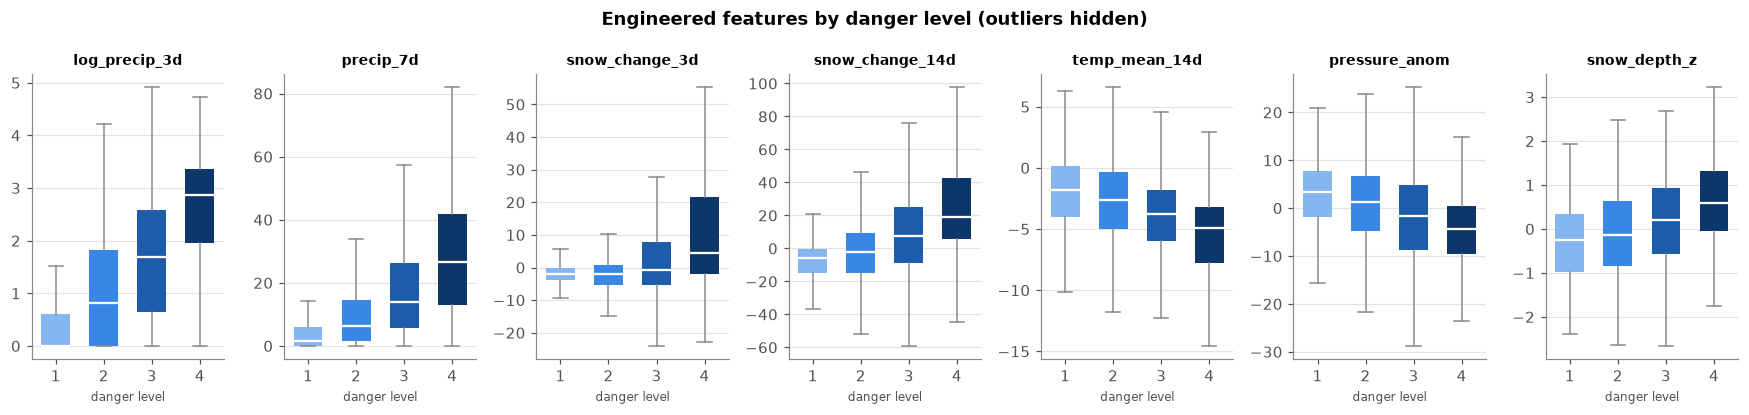

In [38]:
show = ["log_precip_3d", "precip_7d", "snow_change_3d", "snow_change_14d", "temp_mean_14d", "pressure_anom", "snow_depth_z"]
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.8))
for ax, col in zip(axes, show):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in LEVELS]
    bp = ax.boxplot(groups, tick_labels=LEVELS, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": GREY}, capprops={"color": GREY})
    for patch, l in zip(bp["boxes"], LEVELS):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(col, fontsize=9); ax.set_xlabel("danger level", fontsize=8); ax.grid(axis="x", visible=False)
fig.suptitle("Engineered features by danger level (outliers hidden)", fontweight="bold")
plt.tight_layout()

data.groupby("danger_max")[show].median().T

The medians of all engineered features change monotonically from level 1 to level 4. Compared to the raw variables in 4.1, the boxes of the levels are better separated, especially for `log_precip_3d` and `snow_change_14d`. Levels 2 and 3 still overlap.

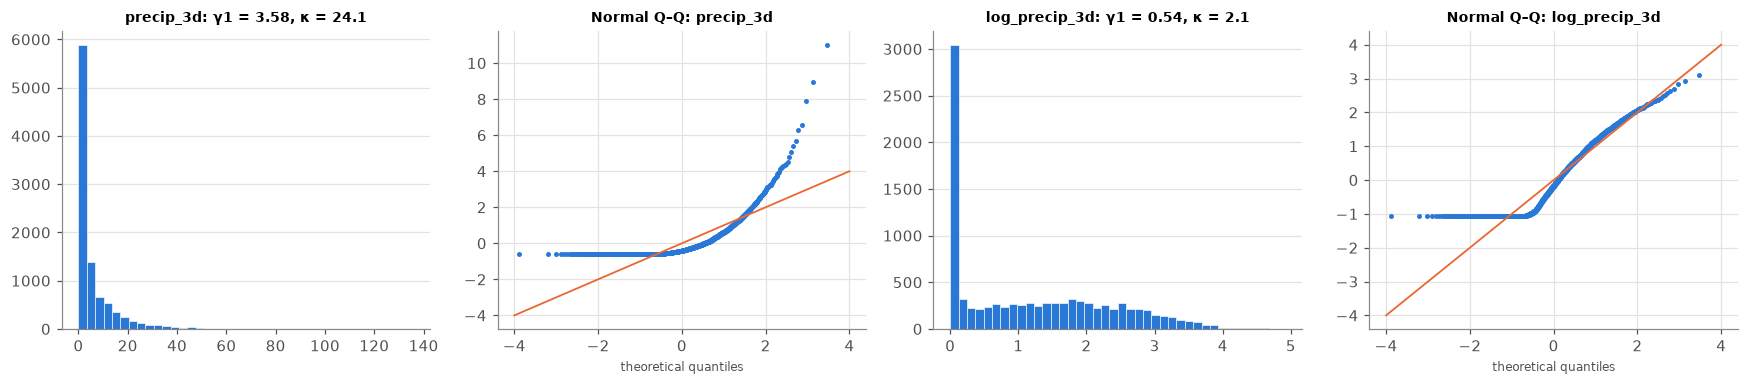

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for k, col in enumerate(["precip_3d", "log_precip_3d"]):
    x = data[col].dropna()
    axes[2 * k].hist(x, bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    axes[2 * k].set_title(f"{col}: γ1 = {moment_shape(x)[0]:.2f}, κ = {moment_shape(x)[1]:.1f}", fontsize=9)
    axes[2 * k].grid(axis="x", visible=False)
    xs = np.sort(x.values); n = len(xs)
    theo = np.array([NormalDist().inv_cdf(q) for q in (np.arange(1, n + 1) - 0.5) / n])
    z = (xs - xs.mean()) / xs.std(ddof=1)
    axes[2 * k + 1].scatter(theo[::6], z[::6], s=5, color=BLUE)
    axes[2 * k + 1].plot([-4, 4], [-4, 4], color=ORANGE, lw=1.2)
    axes[2 * k + 1].set_title(f"Normal Q–Q: {col}", fontsize=9)
    axes[2 * k + 1].set_xlabel("theoretical quantiles", fontsize=8)
plt.tight_layout()

The log transformation reduces the skewness and kurtosis of the 3-day precipitation strongly. The distribution is still not normal (the dry days form a block at 0 in the Q–Q plot), but the long right tail is gone. This makes it much better suited for linear models.

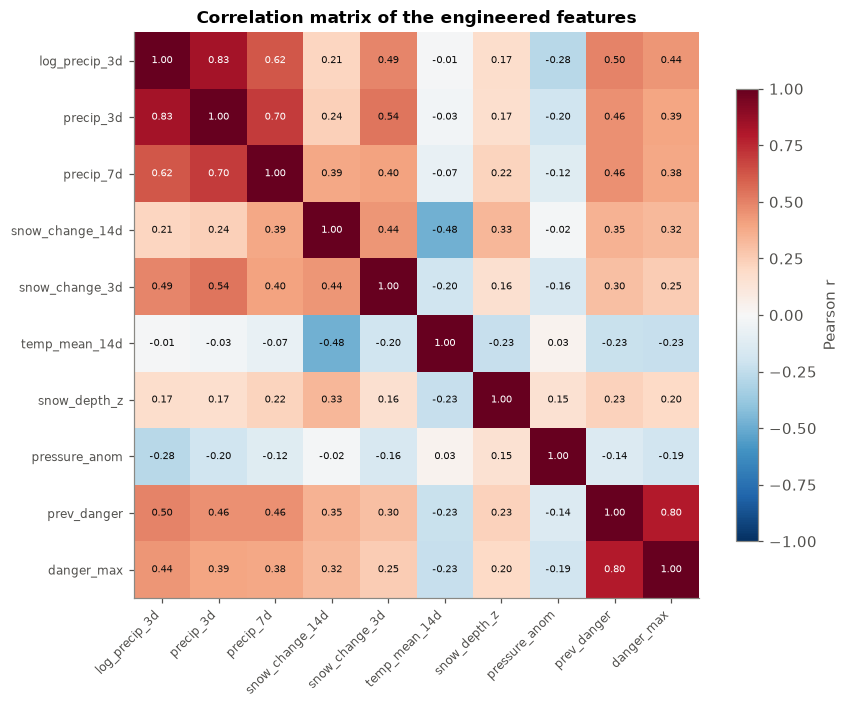

In [40]:
cols = list(ENG_NUM) + ["prev_danger", "danger_max"]
c = data[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(c)), c.index, fontsize=8)
for i in range(len(c)):
    for j in range(len(c)):
        v = c.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix of the engineered features")
plt.tight_layout()

* `precip_3d`, `precip_7d` and `log_precip_3d` are strongly correlated with each other (they share the same days). For a linear model we keep one or two of them (e.g. `log_precip_3d` + `precip_7d`), trees can use all.
* `snow_change_3d` is strongly correlated with `precip_3d` (r ≈ 0.54): both measure the fresh snow of the last days. `snow_change_14d` and `temp_mean_14d` are moderately negatively correlated (−0.48: warm periods let the snowpack settle).
* `snow_depth_z`, `pressure_anom` and `temp_mean_14d` are only weakly correlated with the precipitation features, so they add **different** information.

**Consequences:** the modelling notebook will use the raw weather variables plus these engineered features. Feature set A: weather only (raw + engineered). Feature set B: A + `prev_danger`, to separate the weather signal from persistence.

---
## 5. Summary: how the EDA informs the next steps

| Finding | Method | Consequence |
|---|---|---|
| Target is ordinal and imbalanced (51% level 2, 4% level 4, no level 5) | tabulation, bar chart | majority-class baseline; macro-F1, per-class recall, confusion matrix; class weights; level 5 cannot be learned |
| ~79% of days keep yesterday's level | cross-tabulation | persistence baseline (predict yesterday's level); split train/test **by season**, not randomly |
| Seasons differ strongly (level-4 share 1–6.5%) | cross-tabulation | evaluate on several seasons (leave-one-season-out) |
| Precipitation, wind, gusts, sunshine: right-skewed, heavy tails, many zeros | location, spread, shape, histogram, Q–Q plot | log transformation / robust scaling for linear models; use median/IQR in reporting |
| Statistical "outliers" in precipitation are real storm days with high danger | z-score / IQR / MAD rules, statistics by category | **do not remove** them |
| Pressure and snow depth are multimodal because of station elevation; overall correlations are confounded by station | histograms (bin width), violin plots, scatterplot with subgroups | normalise per station (deviation from station mean) and/or include region as a feature |
| Temperature effect differs between mid-winter and spring | scatterplot with subgroups, grouped boxplots | include month; prefer models that learn interactions (trees), or add temperature × spring |
| Precipitation, humidity, gusts, sunshine, snow depth relate weakly–moderately to the level; no single strong predictor | correlation, grouped boxplots, scatterplot matrix | combine several features; expect most confusion between levels 2 and 3 |
| Temperatures (mean/min/max) and wind/gusts are highly correlated | correlation matrix, heatmap | keep one per group for linear models |
| Multi-day sums/changes and station-normalised features correlate more strongly with the level than the raw variables | correlation, grouped boxplots (4.5) | use the engineered features from the feature engineering block; fit station statistics on training seasons only |

**No further data cleaning is required from this EDA**: there are no missing weather values, no impossible values, and the extreme values are real events. The changes are transformations and features (all collected in the feature engineering block at the top) and decisions for the evaluation setup.